# Final Report Template: Title Here

**List group members and collaborators here**

This template is to help guide you in preparing your final report. We will use the 8 step machine learning work flow to structure the final report. In each section, there are some questions and tasks that typical machine learning projects should follow. Discuss in your final report all relavant questions and investigations your group did in those parts. Your grade will be based on your explanations of the choices your made and how they impact your science question and models. 

You will turn in a written lab report and a separate Jupyter notebook with your calculations and work. Be sure to include an abstract in the beginning of your lab write up. You will upload all of this, including your data into a Google Drive that is linked in the template in Jupyterhub. The final project notebook template and rubrics should be available now if you clone the labs.

Your lab report should be written as a separate document from your Jupyter notebook / code. It should include an abstract, and be structured with sections similar to the template. The report should be written in paragraphs as a narrative that discusses the questions within the template. Even if some of the questions do not apply, you should say why. For example, some datasets were obtained from existing papers or was already cleaned so data cleaning was not necessary. The writeup should include plots that should be referenced in the text. You should also upload all code and data necessary to reproduce your work, including the creation of the plots. If the original dataset is too large to upload, upload your features that you created from the original dataset that was used to train the model instead. 

Please also upload your final presentation when you upload the rest of the material. 



**Make sure to include all code and data in the upload as well**

**Please see BruinLearn for the Google Drive link to upload the final project components** 



In [ ]:

import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "1"


In [51]:
import torch

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using:", device)


Using: cpu


In [52]:
import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.cluster import KMeans
from dataclasses import dataclass
from matplotlib import cm
from matplotlib.animation import FuncAnimation, PillowWriter
from dataclasses import asdict
from itertools import product
from pathlib import Path
import json

In [53]:
# Check, if I can use the GPU on Macbook
print(torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("MPS built:    ", torch.backends.mps.is_built())

2.10.0
MPS available: False
MPS built:     True


In [54]:
# If one wants to use the Macbook GPU, it is essential to turn all torch tensors to float32s
# I was able to run it on my MPS, but it was still slower than the JupyterHub :(
if torch.backends.mps.is_available():
    device = torch.device("mps")
    torch.set_default_dtype(torch.float32)
elif torch.cuda.is_available():
    device = torch.device("cuda")  # fallback, won't apply on your Mac
else:
    device = torch.device("cpu")

## Abstract

The abstract should give a summary of your science question as well as your findings. What are some lessons learned in this work?

## Part 1  Big Picture 

1. Define the science question or objective.
2. How will your solution be used?
3. What are the current solutions/workarounds (if any)?
4. How should you frame this problem (supervised/unsupervised, online/offline, etc.)?
5. How should performance be measured?
6. Is the performance measure aligned with the scientific objective?
7. What would be the minimum performance needed to reach the scientific objective?
8. What are comparable problems? Can you reuse experience or tools?
9. Is human expertise available?
10. How would you solve the problem manually?
11. List the assumptions you (or others) have made so far.
12. Verify assumptions if possible.



1. **Science question / objective**  
In typical flow matching the objective is to map an initial data distribution to a final data distribution and in standard implementations, the maps do not adhere to the data manifold strictly. We wish to add to this discussion by constructing flows which have support only on the data manifold. This project asks whether a metric aware neural transport model can learn smooth, geodesic motion between source and target distributions on nontrivial manifolds in $\mathbb{R}^3$, specifically a sphere, a torus, and a genus-2 surface.   

2. **How the solution will be used**  
The solution is used as a controlled benchmark for manifold aware transport and flow learning. It demonstrates whether learned paths respect geometry/topology while moving mass from one distribution to another. Another way to phrase this would be say that we wish to construct curved interpolants mapping an initial data distribution to a final ! 

3. **Current solutions / workarounds**  
Common baselines include Euclidean interpolation, optimal transport in ambient space, and generic flow models that do not explicitly encode manifold geometry. A typical workaround is to ignore geometry and rely on high model capacity, which can produce unrealistic paths where the intermediate states do not adhere to the data manifold ! 

4. **Problem framing**  
This is a learning problem where the  source and target samples are available. The training pipeline has two stages: learn an interpolant path, then learn a velocity field that reproduces that path.

5. **How performance is measured**  
Primary metrics are the metric weighted interpolant loss ("kinetic energy" objective) and the metric-weighted velocity matching loss. Secondary evaluation uses qualitative checks: trajectory smoothness, topology respecting motion, and endpoint overlap with the target distribution.

6. **Is the metric aligned with the scientific objective?**  
Yes. The objective penalizes path energy under a learned metric, which directly supports the goal of geometry aware transport instead of purely Euclidean straight line motion.

7. **Minimum performance needed**  
At minimum, training must converge stably, transported endpoints must overlap target modes, and trajectories should avoid obvious of manifold artifacts or topologically invalid shortcuts.

8. **Comparable problems and reusable tools**  
Comparable areas are manifold optimal transport, geodesic regression, and flow matching.

9. **Human expertise available**  
Human/domain expertise is available from geometry intuition and course context: known structures of sphere/torus/genus-2 and expected valid transport behavior.

10. **Manual solution approach**  
A manual baseline would prescribe analytic/heuristic paths in manifold coordinates (e.g., angular motion on sphere/torus and handle avoiding routes on genus-2), then map those paths back to $\mathbb{R}^3$.

11. **Assumptions made so far**  
 
- A scalar RBF metric is sufficient to capture relevant geometry.  
- Arbitrary source target pairing is acceptable for training objectives.  
- Finite step Euler integration approximates continuous flow well enough.  
- Synthetic datasets are representative stress-tests for topology-aware transport.

12. **How assumptions are verified**  
Assumptions are checked by metric visualizations (3D clouds and 2D slices), transport trajectory plots/animations, endpoint target overlap, and hyperparameter/seed sensitivity during optimization.


## Part 2 Get the Data

1. Describe the data you need and how much you need.
2. Find and document where you can get that data.
3. Check how much space it will take.
4. If necessary, check legal obligations, and get authorization if necessary.
5. If necessary, get access authorizations.
6. Create a workspace (with enough storage space).
7. Get the data.
8. Convert the data to a format you can easily manipulate (without changing the data itself).
9. Ensure sensitive information is deleted or protected (e.g., anonymized).
10. Check the size and type of data (time series, sample, geographical, etc.).
11. Sample a test set, put it aside, and never look at it (no data snooping!).


1. **Data needed and amount**  
We need paired source/target point clouds in $\mathbb{R}^3$ for three geometries: sphere, torus, and genus-2. Typical runs use $n \sim 3500$ to $4000$ points per source and target set ! 

2. **Where the data comes from**  
The dataset is generated locally in the notebook using custom sampling functions.

3. **Storage requirements**  
Storage needs are small (arrays and model checkpoints only). This comfortably fits local notebook storage.

4. **Legal / authorization checks**  
No external or sensitive dataset is used, so no licensing or access authorization is required.

5. **Workspace setup**  
All generation, training, plots, and checkpoints are created inside the project notebook/workspace.

6. **Data acquisition process**  
“Acquisition” is deterministic generation with fixed seeds, which improves reproducibility across reruns.

7. **Manipulable format**  
Generated data is stored as NumPy arrays and converted to PyTorch tensors (`float32`) for training on MacBook GPU.

8. **Sensitive information handling**  
Not applicable; data is synthetic and contains no personal or protected information ! 

9. **Data type/structure checks**  
Each dataset is verified as 3D point-cloud data with expected manifold structure, specifically in the following contexts 
- sphere shell
- torus tube around ring
- genus 2 two handle structure

10. **Train/test split policy**  
Because data is generated on demand, separate held out samples can be generated with different seeds. Current workflow focuses on train/eval losses and qualitative transport checks; a strict held-out split can be added by reserving independent seeds.

11. **Reproducibility note**  
Fixed random seeds and explicit generation parameters define the dataset specification, so experiments can be reproduced exactly.


# Creating the Data

In this section, we will create three different toy datasets on which we want to test the neural network:

1. A sphere with initial and final data on north and south pole.
2. A torus with initial and final data on a cricle that follows a torus cycle.
3. A genus-2 surface. Here, we want to test, how well the network deals with splitting the data up and sending it on periodic cycles.

## Creating Sphere Data

In [55]:
# Since we will use it a lot, we define:
TAU = 2 * np.pi

# Create spherical points
def sphere_angles(theta, phi):
    return np.column_stack([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])

# Sample a near north and south pole with tails towards the equator
def sample_sphere_north_south_with_tails(n, core_sigma, tail_sigma, tail_frac, thickness_sigma, seed):

    # Set up the seed and the fraction of samples in tail and core
    rng = np.random.default_rng(seed)
    n_tail = int(round(tail_frac*n))
    n_core = n - n_tail

    # Sample phi
    phi0 = TAU * rng.random(n)
    phi1 = TAU * rng.random(n)

    # Sample cores at the poles
    theta0_core = np.abs(core_sigma * rng.normal(size=n_core))
    theta1_core = np.pi - np.abs(core_sigma * rng.normal(size=n_core))

    # Sample tails
    theta0_tail = np.abs(tail_sigma * rng.normal(size=n_tail))
    theta1_tail = np.pi - np.abs(tail_sigma * rng.normal(size=n_tail))

    # Glue initial and final together
    theta0 = np.concatenate([theta0_core, theta0_tail])
    theta1 = np.concatenate([theta1_core, theta1_tail])
    theta0 = np.clip(theta0, 0.0, 0.68 * np.pi)
    theta1 = np.clip(theta1, 0.32 * np.pi, np.pi)

    # Embed in R^3
    x0 = sphere_angles(theta0, phi0)
    x1 = sphere_angles(theta1, phi1)

    if thickness_sigma > 0.0:
        x0 = (1.0 + thickness_sigma * rng.normal(size=(n,1))) * x0
        x1 = (1.0 + thickness_sigma * rng.normal(size=(n,1))) * x1

    # Randomize Order
    perm0 = rng.permutation(n)
    perm1 = rng.permutation(n)

    return x0[perm0], x1[perm1]

    

## Creating Torus Data

In [56]:
# For the Torus, we will often identify
def wrap_angle(x):
    return np.mod(x, TAU)

# Toroidal Coordinates
def torus_embed(z, R, r):
    u = z[:, 0:1]
    v = z[:, 1:2]
    cv, sv = np.cos(v), np.sin(v)
    cu, su = np.cos(u), np.sin(u)
    ring = R + r * cv
    return np.hstack([ring * cu, ring * su, r * sv])

# Unit Torus
def torus_normal(z):
    u = z[:, 0:1]
    v = z[:, 1:2]
    return np.hstack([np.cos(u) * np.cos(v), np.sin(u) * np.cos(v), np.sin(v)])

# Samples the Torus
def sample_torus_posnegx(n, sigma_u_core, sigma_u_tail, tail_frac, sigma_v_pair, thickness_sigma, R, r, seed):

    # Set Seed and data ratios
    rng = np.random.default_rng(seed)
    n_tail = int(round(tail_frac * n))
    n_core = n - n_tail

    # Generate data on cycle
    v0 = TAU * rng.random((n, 1))
    v1 = wrap_angle(v0 + sigma_v_pair * rng.normal(size=(n, 1)))

    # Generate Cores and Tails
    u0_core = sigma_u_core * rng.normal(size=(n_core, 1))
    u1_core = np.pi + sigma_u_core * rng.normal(size=(n_core, 1))

    u0_tail = np.abs(sigma_u_tail * rng.normal(size=(n_tail, 1)))
    u1_tail = np.pi - np.abs(sigma_u_tail * rng.normal(size=(n_tail, 1)))

    # Combine angles
    u0 = np.vstack([u0_core, u0_tail])
    u1 = np.vstack([u1_core, u1_tail])
    z0 = np.hstack([u0, v0])
    z1 = np.hstack([u1, v1])

    # Embed Torus in R^3
    x0 = torus_embed(z0, R,r)
    x1 = torus_embed(z1, R, r)

    # Thicken torus
    if thickness_sigma > 0.0:
        x0 = x0 + thickness_sigma*rng.normal(size=(n,1))*torus_normal(z0)
        x1 = x1 + thickness_sigma*rng.normal(size=(n,1))*torus_normal(z1)

    perm = rng.permutation(n)
    return x0[perm], x1[perm]
    

## Creating Genus-2 Data

In [57]:
def _normalize_rows(x, eps: float=10e-12):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), eps, None)

# Sample points in a small tube around a given two-dimensional surface
def _sample_tube_points(
    centers,
    tangents,
    tube_radius,
    thickness_sigma,
    rng):
    z_axis = np.array([0.0, 0.0, 1.0], dtype=np.float64)
    alt_axis = np.array([0.0, 1.0, 0.0], dtype=np.float64)

    t = _normalize_rows(tangents)
    ref = np.repeat(z_axis[None, :], t.shape[0], axis=0)
    use_alt = np.abs((t * ref).sum(axis=1, keepdims=True)) > 0.92
    ref = np.where(use_alt, alt_axis[None, :], ref)

    n1 = np.cross(t, ref)
    n1 = _normalize_rows(n1)
    n2 = np.cross(t, n1)
    n2 = _normalize_rows(n2)

    psi = TAU * rng.random((centers.shape[0], 1))
    radial_dir = np.cos(psi) * n1 + np.sin(psi) * n2
    radius = tube_radius + thickness_sigma * rng.normal(size=(centers.shape[0], 1))
    return centers + radius * radial_dir

# Create a loop on the left
def _left_loop_center(theta, a, R):
    return np.column_stack([-a + R * np.cos(theta), R * np.sin(theta), np.zeros_like(theta)])

# Create a tangent to left loop
def _left_loop_tangent(theta, R):
    return np.column_stack([-R * np.sin(theta), R * np.cos(theta), np.zeros_like(theta)])

# Create a loop on the right
def _right_loop_center(theta, a, R):
    return np.column_stack([a + R * np.cos(theta), R * np.sin(theta), np.zeros_like(theta)])

# Create a tangent to right loop
def _right_loop_tangent(theta, R):
    return np.column_stack([-R * np.sin(theta), R * np.cos(theta), np.zeros_like(theta)])

# Create a Bridge
def _bridge_center(s, x_left, x_right):
    x = x_left + (x_right - x_left) * s
    return np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])

# Create a tanget to the bridge
def _bridge_tangent(s):
    return np.column_stack([np.ones_like(s), np.zeros_like(s), np.zeros_like(s)])


def sample_genus2_surface_background(
    n,
    a,
    loop_R,
    tube_r,
    thickness_sigma,
    seed):
    rng = np.random.default_rng(seed)
    x_left = -a + loop_R
    x_right = a - loop_R
    lengths = np.array([TAU * loop_R, TAU * loop_R, x_right - x_left], dtype=np.float64)
    probs = lengths / lengths.sum()
    pieces = rng.choice(3, size=n, p=probs)
    pts = []
    for piece in range(3):
        m = int(np.sum(pieces == piece))
        if m == 0:
            continue
        if piece == 0:
            theta = TAU * rng.random(m)
            centers = _left_loop_center(theta, a, loop_R)
            tangents = _left_loop_tangent(theta, loop_R)
        elif piece == 1:
            theta = TAU * rng.random(m)
            centers = _right_loop_center(theta, a, loop_R)
            tangents = _right_loop_tangent(theta, loop_R)
        else:
            s = rng.random(m)
            centers = _bridge_center(s, x_left, x_right)
            tangents = _bridge_tangent(s)
        pts.append(_sample_tube_points(centers, tangents, tube_r, thickness_sigma, rng))
    return np.vstack(pts)


def sample_genus2_data(
    n: int,
    a: float,
    loop_R: float,
    tube_r: float,
    thickness_sigma: float,
    seed: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    n_tail = int(round(0.28 * n))
    n_core = n - n_tail
    x_left = -a + loop_R
    x_right = a - loop_R

    # Source core: bridge midpoint, top side.
    s0 = np.clip(0.5 + 0.10 * rng.normal(size=n_core), 0.30, 0.70)
    c0 = _bridge_center(s0, x_left, x_right)
    t0 = _bridge_tangent(s0)
    psi0 = np.clip(math.pi / 2 + 0.32 * rng.normal(size=(n_core, 1)), 0.0, math.pi)
    x0_core = _sample_tube_points(c0, t0, tube_r, 0.0, rng)
    # Re-orient source core to the top side for a cleaner central mode.
    x0_core = c0 + tube_r * np.column_stack([np.zeros(n_core), np.cos(psi0[:, 0]), np.sin(psi0[:, 0])])
    if thickness_sigma > 0.0:
        radial = _normalize_rows(x0_core - c0)
        x0_core = x0_core + thickness_sigma * rng.normal(size=(n_core, 1)) * radial

    # Blue source tails:
    # - one lower-half loop on the left handle from 3 o'clock to 9 o'clock
    # - one upper-left loop on the right handle from 9 o'clock to 12 o'clock
    n_tail_left = int(round(0.52 * n_tail))
    n_tail_right = n_tail - n_tail_left
    n_tail_left_bridge = int(round(0.38 * n_tail_left))
    n_tail_left_loop = n_tail_left - n_tail_left_bridge

    s_left_bridge = np.clip(0.5 - 0.50 * rng.random(n_tail_left_bridge), 0.0, 0.5)
    c_left_bridge = _bridge_center(s_left_bridge, x_left, x_right)
    t_left_bridge = _bridge_tangent(s_left_bridge)
    x0_tail_left_bridge = _sample_tube_points(
        c_left_bridge, t_left_bridge, tube_r, thickness_sigma, rng
    )

    # Lower half: 3 o'clock -> 9 o'clock clockwise.
    theta_left_long = rng.uniform(math.pi, TAU, size=n_tail_left_loop)
    c_left_long = _left_loop_center(theta_left_long, a, loop_R)
    t_left_long = _left_loop_tangent(theta_left_long, loop_R)
    x0_tail_left_long = _sample_tube_points(
        c_left_long, t_left_long, tube_r, thickness_sigma, rng
    )

    # Right handle blue tail: 9 o'clock -> 12 o'clock.
    theta_right_blue = rng.uniform(math.pi, 1.5 * math.pi, size=n_tail_right)
    c_right_blue = _right_loop_center(theta_right_blue, a, loop_R)
    t_right_blue = _right_loop_tangent(theta_right_blue, loop_R)
    x0_tail_right = _sample_tube_points(
        c_right_blue, t_right_blue, tube_r, 0.8 * thickness_sigma, rng
    )

    x0 = np.vstack([x0_core, x0_tail_left_bridge, x0_tail_left_long, x0_tail_right])

    # Target: bimodal, with one mode on right outer end and one close to the bridge on the left.
    n_tgt_right = int(round(0.58 * n))
    n_tgt_left = n - n_tgt_right

    # Right target: outer lobe core plus a right-handle upper arc from 12 to 3,
    # with no red core placed in the middle bridge region.
    n_tgt_right_tail = max(1, int(round(0.24 * n_tgt_right)))
    n_tgt_right_core = n_tgt_right - n_tgt_right_tail

    theta_tgt_right = np.clip(
        0.0 + 0.18 * rng.normal(size=n_tgt_right_core),
        -0.45,
        0.45,
    )
    c1r = _right_loop_center(theta_tgt_right, a, loop_R)
    t1r = _right_loop_tangent(theta_tgt_right, loop_R)
    x1_right_core = _sample_tube_points(c1r, t1r, tube_r, thickness_sigma, rng)

    theta_tgt_right_tail = rng.uniform(1.5 * math.pi, TAU, size=n_tgt_right_tail)
    c1r_tail = _right_loop_center(theta_tgt_right_tail, a, loop_R)
    t1r_tail = _right_loop_tangent(theta_tgt_right_tail, loop_R)
    x1_right_tail = _sample_tube_points(
        c1r_tail, t1r_tail, tube_r, 0.65 * thickness_sigma, rng
    )

    x1_right = np.vstack([x1_right_core, x1_right_tail])

    # Left target is split into:
    # - a compact mode around 12 o'clock
    # - a red arc tail from 12 o'clock to 9 o'clock
    # The blue and red left tails meet near 9 o'clock.
    n_tgt_left_tail = max(1, int(round(0.24 * n_tgt_left)))
    n_tgt_left_core = n_tgt_left - n_tgt_left_tail

    theta_tgt_left_core = np.clip(
        0.5 * math.pi + 0.12 * rng.normal(size=n_tgt_left_core),
        0.30 * math.pi,
        0.70 * math.pi,
    )
    c1l_core = _left_loop_center(theta_tgt_left_core, a, loop_R)
    t1l_core = _left_loop_tangent(theta_tgt_left_core, loop_R)
    x1_left_core = _sample_tube_points(c1l_core, t1l_core, tube_r, thickness_sigma, rng)

    theta_tgt_left_tail = rng.uniform(0.50 * math.pi, math.pi, size=n_tgt_left_tail)
    c1l_tail = _left_loop_center(theta_tgt_left_tail, a, loop_R)
    t1l_tail = _left_loop_tangent(theta_tgt_left_tail, loop_R)
    x1_left_tail = _sample_tube_points(
        c1l_tail, t1l_tail, tube_r, 0.55 * thickness_sigma, rng
    )

    x1_left = np.vstack([x1_left_core, x1_left_tail])

    x1 = np.vstack([x1_right, x1_left])

    background = sample_genus2_surface_background(
        n=22000,
        a=a,
        loop_R=loop_R,
        tube_r=tube_r,
        thickness_sigma=0.0,
        seed=seed + 101,
    )
    return x0[rng.permutation(n)], x1[rng.permutation(n)], background

## Part 3 Explore the Data

Note: try to get insights from a domain expert for these steps.
1. Create a copy of the data for exploration (sampling it down to a manageable size if necessary) (Done !).
2. Create a Jupyter notebook to keep a record of your data exploration (Done !). 
3. Study each attribute and its characteristics: Name
Type (categorical, int/float, bounded/unbounded, text, structured, etc.)
% of missing values
Noisiness and type of noise (stochastic, outliers, rounding errors, etc.)
Usefulness for the task
Type of distribution (Gaussian, uniform, logarithmic, etc.)
4. For supervised learning tasks, identify the target attribute(s).
5. Visualize the data.
6. Study the correlations between attributes.
7. Study how you would solve the problem manually.
8. Identify the promising transformations you may want to apply (Does not apply for our context ! ). 
9. Identify extra data that would be useful (go back to “Get the Data”).
10. Document what you have learned.


### Part 3: Attribute Study (Rubric Q3 and Q4)
For this project, each dataset (sphere, torus, genus-2) is represented as 3D point clouds:
- source set: `x0` with shape `(n, 3)`
- target set: `x1` with shape `(n, 3)`

#### 3) Attribute characteristics

| Attribute | Type | Missing values | Noise / noisiness | Usefulness for task | Distribution |
|---|---|---:|---|---|---|
| `x` coordinate | Continuous float (`float32`), bounded by geometry construction | 0% | Controlled stochastic noise from sampling (core/tail spread, angular perturbations, thickness noise); intentional outlier-like tails | Essential | Non-Gaussian, multimodal, manifold-supported |
| `y` coordinate | Continuous float (`float32`), bounded by geometry construction | 0% | Same as above | Essential | Non-Gaussian, multimodal, manifold-supported |
| `z` coordinate | Continuous float (`float32`), bounded by geometry construction | 0% | Same as above | Essential | Non-Gaussian, multimodal, manifold-supported |
| Dataset role (`source` vs `target`) | Categorical (binary) | 0% | None | Used to define transport direction (`x0 -> x1`) | Two-group split, not a probability feature |
| Time input `t` (sampled during training) | Continuous float in `[0,1]`, bounded | 0% | Random sampling noise by design (uniform draws) | Essential for interpolant/velocity models | Approximately uniform by construction |

**Dataset-specific distribution notes**
- **Sphere:** points lie near a spherical shell with pole-centered modes plus tails toward equator.  
- **Torus:** points lie near torus surface with periodic angular structure and opposite-side modes.  
- **Genus-2:** points lie near a two-handle/bridge structure with stronger multimodality and asymmetric tails.

#### 4) Target attribute(s) for supervised learning

This is **not a standard label-supervised task** (no class labels).  
Targets are defined by the training objective:

- **Interpolant network (`phi_net`)**: trained with a metric-weighted energy objective (self-/weakly-supervised), not direct labels.
- **Velocity network (`v_net`)**: supervised regression target is `x_t_dot` computed from the interpolant path derivative.
- At endpoint level, `x1` acts as the target distribution for transport from `x0`.

So,  
- primary target for endpoint transport is **target point cloud `x1`** (distributional target),  
- primary target for velocity regression is **`x_t_dot`**.


# Visualizing the Data

In this section, we are going to visualize the data. For this, we will write nice plotting functions.

## Visualizing the Sphere Data

In [58]:
# Plotting the Sphere Data
def plot_sphere(ax, x0, x1):
    u = np.linspace(0.0, 2.0 * np.pi, 60)
    v = np.linspace(0.0, np.pi, 35)
    sx = np.outer(np.cos(u), np.sin(v))
    sy = np.outer(np.sin(u), np.sin(v))
    sz = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_wireframe(sx, sy, sz, color = "black", linewidth=0.4, alpha = 0.28)
    ax.scatter(x0[:,0], x0[:,1], x0[:,2], s=7, alpha=0.35, c="b", label="source")
    ax.scatter(x1[:,0], x1[:,1], x1[:,2], s=7, alpha=0.35, c="r", label="source")
    ax.set_title("Sphere: Data on poles with tails to equator")
    ax.set_xlim([-1.2, 1.2])
    ax.set_ylim([-1.2, 1.2])
    ax.set_zlim([-1.2, 1.2])
    ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=24, azim=-60)
    

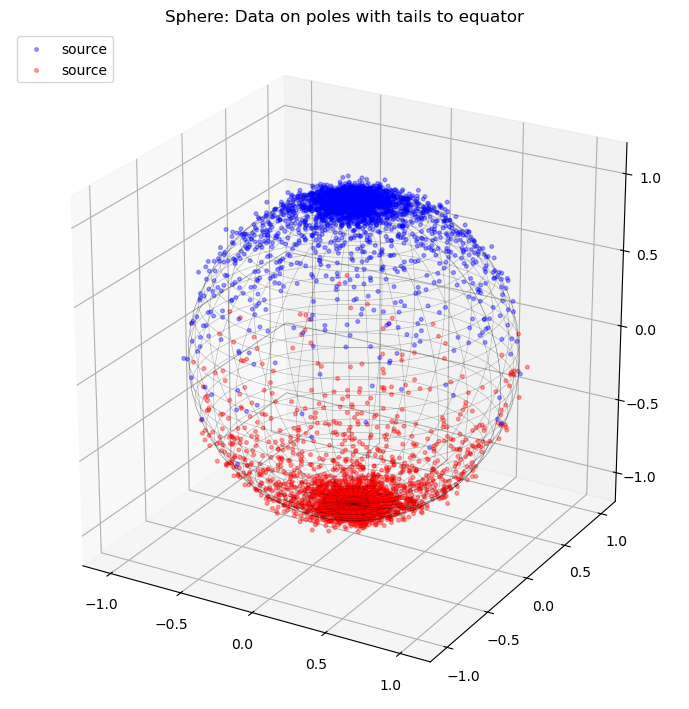

In [7]:
sphere_x0, sphere_x1 = sample_sphere_north_south_with_tails(
    n=3500,
    core_sigma=0.14,
    tail_sigma=0.62,
    tail_frac=0.42,
    thickness_sigma=0.03,
    seed=17,
)

fig = plt.figure(figsize=(8.6, 7.2))
ax = fig.add_subplot(111, projection="3d")
plot_sphere(ax, sphere_x0, sphere_x1)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


**Observation** 
 
The source and target distributions are concentrated near opposite poles with visible tails extending toward mid-latitudes. The classes are clearly separated in position, but each class has nontrivial spread due to angular noise and radial thickness.

**Implication for modeling**  

A straight Euclidean interpolation between endpoints can pass through regions that are not representative of the spherical shell geometry. The tail structure also means the transport map must handle both dense cores and lower-density peripheral points. We use a learned RBF metric to reweight transport cost by location and train with metric weighted losses. This encourages smoother, geometry aware trajectories and improves robustness to the core/tail imbalance in the sphere data.


## Visualizing the Torus Data

In [59]:
def plot_torus(ax, x0, x1, R, r):
    uu = np.linspace(0.0, TAU, 54)
    vv = np.linspace(0.0, TAU, 30)
    U, V = np.meshgrid(uu, vv)
    X = (R + r * np.cos(V)) * np.cos(U)
    Y = (R + r * np.cos(V)) * np.sin(U)
    Z = r * np.sin(V)
    ax.plot_wireframe(X, Y, Z, color="black", linewidth=0.4, alpha=0.25)
    ax.scatter(x0[:, 0], x0[:, 1], x0[:, 2], s=7, alpha=0.3, c="b", label="source")
    ax.scatter(x1[:, 0], x1[:, 1], x1[:, 2], s=7, alpha=0.3, c="r", label="target")
    extent = R + r + 0.2
    ax.set_title("Torus: +x to -x cycles")
    ax.set_xlim([-extent, extent])
    ax.set_ylim([-extent, extent])
    ax.set_zlim([-r - 0.25, r + 0.25])
    ax.set_box_aspect([1, 1, 0.62])
    ax.view_init(elev=22, azim=-58)

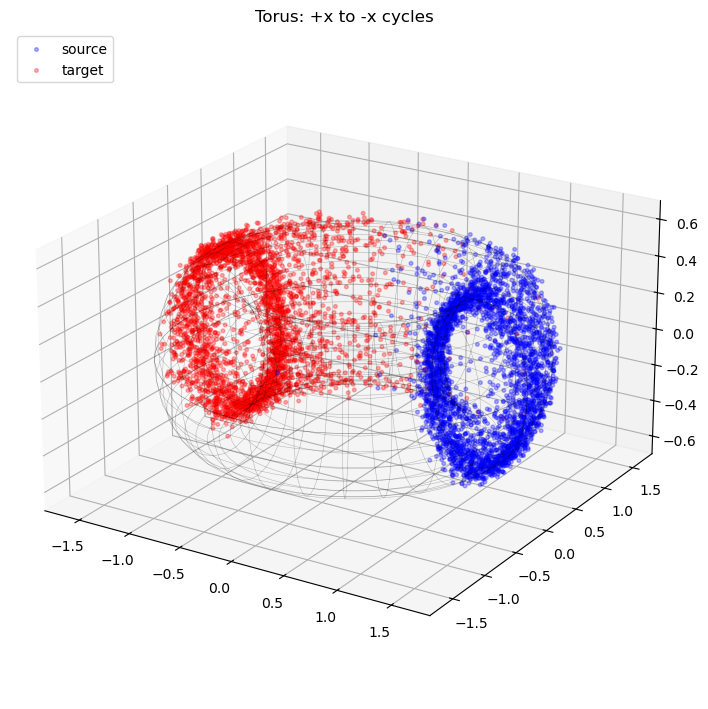

In [10]:
torus_x0, torus_x1 = sample_torus_posnegx(
    n=3500,
    sigma_u_core=0.12,
    sigma_u_tail=0.72,
    tail_frac=0.40,
    sigma_v_pair=0.06,
    thickness_sigma=0.03,
    R=1.2,
    r=0.45,
    seed=30,
)

fig = plt.figure(figsize=(8.6, 7.2))
ax = fig.add_subplot(111, projection="3d")
plot_torus(ax, torus_x0, torus_x1, R=1.2, r=0.45)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


**Observation**  
The source and target points lie on opposite sides of a torus with angular spread in both the major cycle and minor cycle directions. The geometry is periodic, and valid paths should follow toroidal structure rather than cutting through empty ambient regions.

**Implication for modeling**  
Ambient-space shortcuts can violate manifold structure, especially for points separated across the ring. The periodic topology makes this a stronger test of whether learned transport respects geometry instead of relying on Euclidean proximity alone.  We again use the learned RBF metric and metric weighted objectives, and we allocate larger training budgets for the torus runs. This setup is intended to help the model learn topology consistent movement around the toroidal geometry.


## Visualizing Genus-2 Data

In [60]:
def plot_genus2(ax: plt.Axes, x0: np.ndarray, x1: np.ndarray, bg: np.ndarray) -> None:
    ax.scatter(bg[:, 0], bg[:, 1], bg[:, 2], s=1.0, alpha=0.035, c="gray")
    ax.scatter(x0[:, 0], x0[:, 1], x0[:, 2], s=7, alpha=0.35, c="#1f77b4", label="source")
    ax.scatter(x1[:, 0], x1[:, 1], x1[:, 2], s=7, alpha=0.35, c="#d62728", label="target")
    ax.set_title("Genus-2: bridge to lobe / loop-cycle tails")
    ax.set_xlim([-2.2, 2.2])
    ax.set_ylim([-1.55, 1.55])
    ax.set_zlim([-0.95, 0.95])
    ax.set_box_aspect([1.5, 1.05, 0.72])
    ax.view_init(elev=20, azim=-63)

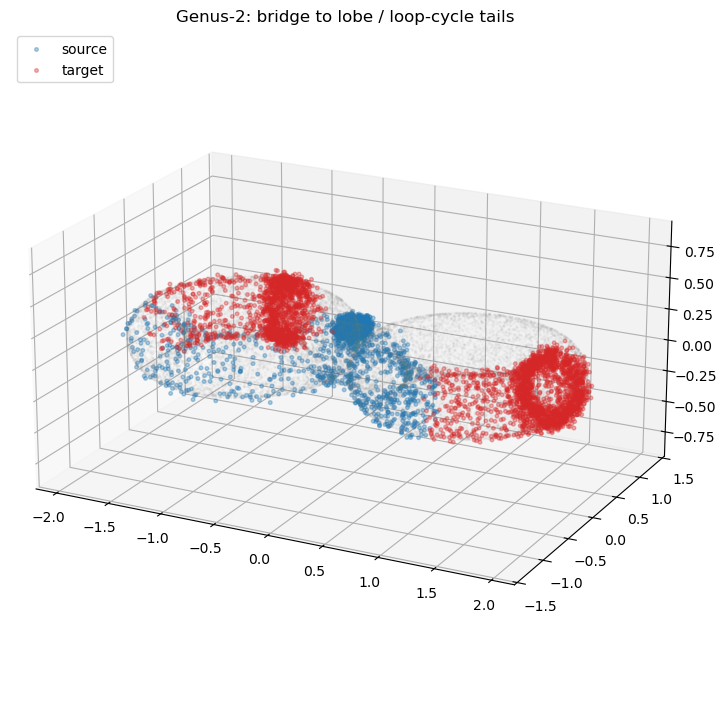

In [61]:
genus2_x0, genus2_x1, genus2_bg = sample_genus2_data(
    n=3500,
    a=1.05,
    loop_R=0.75,
    tube_r=0.24,
    thickness_sigma=0.03,
    seed=46,
)

fig = plt.figure(figsize=(8.6, 7.2))
ax = fig.add_subplot(111, projection="3d")
plot_genus2(ax, genus2_x0, genus2_x1, genus2_bg)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()



**Observation**  
The genus-2 dataset has two handles connected by a bridge, with multimodal source/target placement and asymmetric tails. This introduces branching transport choices and stronger topological constraints than sphere/torus.

**Implication for modeling**  
Naive interpolation is likely to create unrealistic paths that cut across low density regions or ignore handle/bridge structure. The model must learn transport that is both smooth and topology aware under complex geometry.   We use the same metric aware pipeline (RBF metric + metric weighted interpolant and velocity losses) and perform dedicated hyperparameter optimization for genus 2. This is necessary to stabilize learning and capture valid transport behavior on the most complex manifold in the project.



### Rubric 6) Study correlations between attributes

The raw attributes are $(x,y,z)$, and their dependence is strongly manifold-constrained, so simple linear correlation is not the full story ! 

- **Sphere:** points satisfy approximately $x^2+y^2+z^2 \approx 1$, creating strong nonlinear coupling among all three coordinates.
- **Torus:** points satisfy approximately $(\sqrt{x^2+y^2}-R)^2 + z^2 \approx r^2$, so correlation is periodic and geometry-driven.
- **Genus-2:** correlations are piecewise and multimodal because data occupies two handles and a bridge; local structure differs by region.

Conclusion: geometric constraints dominate attribute relationships, so metric-aware modeling is more appropriate than purely linear feature assumptions.

### Rubric 7) How to solve the problem manually

A manual solution would define geometry-respecting paths directly on each manifold:

- **Sphere:** move source points toward target modes along great circles.
- **Torus:** transport mass around the torus cycles (major/minor angles) instead of cutting through ambient space.
- **Genus-2:** choose valid routes through handles/bridge to avoid topologically invalid shortcuts.

This manual baseline motivates learning transport paths that follow manifold geometry rather than Euclidean straight lines.

### Rubric 9) Extra data that would be useful

Useful additions would be:

- Intrinsic coordinates (e.g., angular parameters / chart coordinates) for each point.
- Ground truth correspondences or approximate geodesic trajectories for validation.
- Region labels (handle/bridge membership for genus 2).
- More seeds/noise regimes and larger sample sizes for robustness checks.
- Held out OOD variants (changed geometry/noise) to test generalization.

### Rubric 10) What we learned

- The task is geometry first: attribute relations are nonlinear and manifold constrained.
- Sphere is easiest, torus adds periodic topology, genus-2 is most complex due to branching structure.
- Metric aware objectives are necessary to avoid unrealistic ambient space shortcuts.
- Visual diagnostics (clouds/slices/trajectories) are essential because endpoint MSE alone is not sufficient.
- Hyperparameter tuning matters more as topology complexity increases, especially on genus 2.


## Part 4 Prepare the Data

* Work on copies of the data (keep the original dataset intact) (Done ! ).
* Write functions for all data transformations you apply, for five reasons (Done ! ):
  * So you can easily prepare the data the next time you get a fresh dataset
  * So you can apply these transformations in future projects To clean and prepare the test set
  * To clean and prepare new data instances once your solution is live
  * To make it easy to treat your preparation choices as hyperparameters
  
1. Data cleaning (Done ! ):
  * Fix or remove outliers (optional).
  * Fill in missing values (e.g., with zero, mean, median...) or drop their rows (or columns).
2. Feature selection (optional) (Done ! ):
  * Drop the attributes that provide no useful information for the task.
3. Feature engineering, where appropriate: Discretize continuous features (Done ! ).
  * Decompose features (e.g., categorical, date/time, etc.).
  * Add promising transformations of features (e.g., log(x), 2sqrt(x), x , etc.).
  * Aggregate features into promising new features. 
4. Feature scaling (Done ! ):
  * Standardize or normalize features if necessary. 

## Part 5 Select model and train



**Model Selection and Performance** 


We follow the models, chosen by the authors of [this paper](https://arxiv.org/abs/2405.14780). There are three different models, that we need:
1. Metric Modeling: The authors use a model that uses clustering to find centers in the toy data. We follow their algorithm and describe the metric construction below. There are simpler alternatives to this, but we found this to be the most successful.
2. DNN for Geodesics: The interpolant net is a standard fully connected neural network. We start with a relatively simple setup and then run a hyperparameter tuning later.
3. DNN for Flow Model: Similar to the geodesics, there is no useful alternative to using a deep neural network for this task.

**Significant Variables and Errors**


- The most dangerous part of the workflow is that the three networks are deeply interconnected. They strongly rely on the previous model performing well.
- If the metric learning sets the metric to be primarily flat, then there is nothing for the interpolant network to learn, other than straight paths.
- This also made us decide on the RBF metric over a rather simple Gaussian metric around every point.
- Key hyperparameters in the metric learning are $\kappa$, which controls the Gaussian width and the number of clusters. We found simple $\kappa$'s to work really well. Using too many clusters, increases the training time aggresively. This was not found to be worth it.
- If the metric is good, a large enough interpolant network usually performed really well. The same follows for the velocity field network.
- When integrating the velocity field network, it sometimes happens that the points actually shoot over the final distribution. This can be due to the coarseness of integration steps. One can reduce this by simulating the ODE during training. However, this costs computational time and destroys the idea of the simulation-less flow matching approach. It also defeats the purpose of matching distributions, when integrating the ODE and then using an MSE loss on initial and final point.


**Human Error Avoidance**


If one was to solve this problem analytically, there is no confusion to be had. It is a second order boundary value problem, if one acquires the metric. Getting the metric is a human-made choice. One would probably do hyperparameter tuning by simply staring at the metric plots and deciding, when happy with the overall shape of the metric.


**Feature Engineering and Model Choice**


There is little feature engineering to do. In this simple case, where one knows the manifold, one could obviously add additional terms to the loss functions to enforce that it converges onto the actual metric or that the interpolants fulfill the submanifold constraint. However, this would not generalize to more interesting setups.

# Modeling the Metric

In this section, we will implement the RBF metric from [this paper](https://arxiv.org/abs/2405.14780). We will explain the algorithm in this markdown.


The RBF metric is discussed in more detail in [this paper](https://arxiv.org/pdf/2008.00565). It is a diagonal metric with:
$$g = \text{diag}(\vec{h})$$

The vector $\vec{h}$ is a sum of weighted Gaussians whose centers are determined by running KMeans:
$$h_\alpha(x) = \sum_{k=1}^K \omega_{\alpha,k}(x)\exp\left(-\frac{\lambda_{\alpha,k}}{2}|x_\alpha-\hat{x}_{\alpha, k}|^2\right)$$
where $k$ is the sum over clusters with center $x_k$. We will describe how to find the weight functions $\omega_{\alpha,k}(x)$ for each cluster in the following.

**Clustering Algorithm**


The first step is running a clustering algorithm on the data. The centers will correspond to our data centers and points in the tails. We get:
- Clusters $C_k$: with centers $\hat{x}_k$
- Bandwidths $\lambda_k$ :

$$
\lambda_{\alpha,k}
=
\frac{1}{2}
\left(
\frac{\kappa}{|C_k|}
\sum_{x \in C_k}
\lvert x_{\alpha}-\hat{x}_{\alpha,k}\rvert^2
\right)^{-2}
$$

- The bandwidths approximately correspond to the inverse standard deviation of the cluster. They are a measure of its width. $\kappa$ is a hyperparameter, which squeezes them towards the center, if necessary.


**Learning the Weights**


The additional quantity $\omega_k$ is rather simple. When choosing a number of clusters that is much smaller than the number of data points (as one should), the metric decays exponentially away from the centers. To flatten it out a bit, we introduce weights that are optimized by:
$$\mathcal{L} = \sum_{x_i\in\mathcal{D}}(1-h(x_i))^2$$

This is regressing the function $h$ to be one on all data points.

## RBF Metric

In this section, we want to implement the metric that is suggested in their paper, which they call the RBF metric. To implement it, they are using a KMeans algorithm to identify data centers and then build a metric from there.

In [62]:
# We would like to build a class that can reproduce the metric without any issues for different geometries.

# Getting the Metric includes a fitting procedure. We will save the data
@dataclass
class PaperRBFFitResult:
    final_loss: float
    n_centers: int
    n_steps: int

# We will use a full class to track the metric. The metric should implement a module, since we it carries the data of weights, widths and centers.
class PaperRBFMetricSimple(nn.Module):
    
    # Let us explain all of the fields
    # ambient_dim: Always 3 in our case
    # n_centers: Number of centers, we allow for 
    # kappa: scales Gaussian width
    # alpha: Allows us to scale the importance of the metric
    # eps: Stabilizer in the case of the metric looking locally degenerate
    # min_weight: minimum allowed RBF weights
    # min_sigma: minimum allowed width of a cluster found by KMeans
    def __init__(
        self,
        ambient_dim: int,
        n_centers: int = 100,
        kappa: float = 1.0,
        alpha: float = 1.0,
        eps: float = 1e-3,
        min_weight: float = 1e-4,
        min_sigma: float = 1e-4,
    ) -> None:
        super().__init__()
        self.ambient_dim = ambient_dim
        self.n_centers = n_centers
        self.kappa = kappa
        self.alpha = alpha
        self.eps = eps
        self.min_weight = min_weight
        self.min_sigma = min_sigma

        # To build the metric, we need to save some fitting parameters
        # C will be the center locations
        # lamda will be the precision of the centers
        # W will be the amplitude
        self.register_buffer("C", torch.empty(0, ambient_dim))
        self.register_buffer("lamda", torch.empty(0, 1))
        self.W = nn.Parameter(torch.empty(0, 1), requires_grad=False)
        self.is_initialized = False

    # This implements the Clustering algorithm for finding the centers
    def initialize_from_samples(self, samples: torch.Tensor, seed: int = 0) -> None:
        if samples.ndim != 2 or samples.shape[1] != self.ambient_dim:
            raise ValueError(
                f"samples must have shape (n, {self.ambient_dim}), got {tuple(samples.shape)}"
            )

        # Clustering
        x = samples.detach().cpu().numpy()
        n_clusters = min(self.n_centers, x.shape[0])
        kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=seed)
        labels = kmeans.fit_predict(x)
        centers = kmeans.cluster_centers_

        # Extract approximate wicth of the clusters
        sigmas = np.zeros((n_clusters, 1), dtype=np.float32)
        for k in range(n_clusters):
            points = x[labels == k]
            if points.shape[0] <= 1:
                sigmas[k, 0] = self.min_sigma
                continue
            variance = ((points - centers[k]) ** 2).mean(axis=0)
            sigma = float(np.sqrt(max(variance.mean(), self.min_sigma**2)))
            sigmas[k, 0] = max(sigma, self.min_sigma)

        # To use exactly their formula, we are converting the widths into precisions
        lamda = 0.5 / (self.kappa * sigmas) ** 2
        self.C = torch.tensor(centers, dtype=samples.dtype, device=samples.device)
        self.lamda = torch.tensor(lamda, dtype=samples.dtype, device=samples.device)
        self.W = nn.Parameter(torch.ones(n_clusters, 1, dtype=samples.dtype, device=samples.device))
        self.is_initialized = True

    # This computes the contributions of each cluster to a given data point
    def basis(self, x: torch.Tensor) -> torch.Tensor:
        x = x.to(device=self.C.device, dtype=self.C.dtype)
        d2 = torch.cdist(x, self.C, p=2).pow(2)
        return torch.exp(-0.5 * self.lamda[None, :, :] * d2[:, :, None])

    # This gives the metric density
    def density(self, x: torch.Tensor) -> torch.Tensor:
        phi_x = self.basis(x)
        return (self.W * phi_x).sum(dim=1)

    # This inverts the metric
    def metric_weight(self, x: torch.Tensor) -> torch.Tensor:
        return 1.0 / (self.density(x) + self.eps) ** self.alpha

    # Outputs the actual metric
    def metric_matrix(self, x: torch.Tensor) -> torch.Tensor:
        g = self.metric_weight(x)
        eye = torch.eye(self.ambient_dim, device=x.device, dtype=x.dtype)
        return g.unsqueeze(-1) * eye.unsqueeze(0)

    # Compute the norm of a vector
    def squared_norm(self, x: torch.Tensor, v: torch.Tensor) -> torch.Tensor:
        return self.metric_weight(x) * v.pow(2).sum(dim=1, keepdim=True)


    # Computes the kindetic energy of a vector
    def kinetic_energy(self, x: torch.Tensor, x_dot: torch.Tensor) -> torch.Tensor:
        return self.squared_norm(x, x_dot).mean()


    # This fitting procedure does NOT change the widths or the centers. 
    # CanIt just learns the weights
    def fit(
        self,
        samples: torch.Tensor,
        steps: int = 300,
        lr: float = 1e-2,
        batch_size: int = 512,
        seed: int = 0,
        verbose: bool = True,
    ) -> PaperRBFFitResult:
        self.initialize_from_samples(samples, seed=seed)
        opt = optim.Adam([self.W], lr=lr)
        n = samples.shape[0]
        last_loss = float("nan")

        for step in range(steps):
            idx = torch.randint(0, n, (min(batch_size, n),), device=samples.device)
            x = samples[idx]
            h_x = self.density(x)
            loss = ((1.0 - h_x) ** 2).mean()

            opt.zero_grad()
            loss.backward()
            opt.step()

            with torch.no_grad():
                self.W.data.clamp_(min=self.min_weight)
            last_loss = float(loss.detach().cpu().item())

            if verbose and (step + 1) % max(1, steps // 10) == 0:
                print(f"[paper-rbf-simple] step {step + 1}/{steps} loss={last_loss:.6f}")

        return PaperRBFFitResult(
            final_loss=last_loss,
            n_centers=int(self.C.shape[0]),
            n_steps=steps,
        )

    def save(self, path: str) -> None:
        if not self.is_initialized:
            raise RuntimeError("Metric is not initialized.")
        torch.save(
            {
                "ambient_dim": self.ambient_dim,
                "n_centers": self.n_centers,
                "kappa": self.kappa,
                "alpha": self.alpha,
                "eps": self.eps,
                "min_weight": self.min_weight,
                "min_sigma": self.min_sigma,
                "C": self.C.detach().cpu(),
                "lamda": self.lamda.detach().cpu(),
                "W": self.W.detach().cpu(),
            },
            path,
        )

    @classmethod
    def load(cls, path: str, device: torch.device | None = None) -> "PaperRBFMetricSimple":
        payload = torch.load(path, map_location=device or "cpu")
        metric = cls(
            ambient_dim=int(payload["ambient_dim"]),
            n_centers=int(payload["n_centers"]),
            kappa=float(payload["kappa"]),
            alpha=float(payload["alpha"]),
            eps=float(payload["eps"]),
            min_weight=float(payload["min_weight"]),
            min_sigma=float(payload["min_sigma"]),
        )
        target_device = device or payload["C"].device
        metric.C = payload["C"].to(target_device)
        metric.lamda = payload["lamda"].to(target_device)
        metric.W = nn.Parameter(payload["W"].to(target_device), requires_grad=False)
        metric.is_initialized = True
        return metric


    

## Sphere Metric

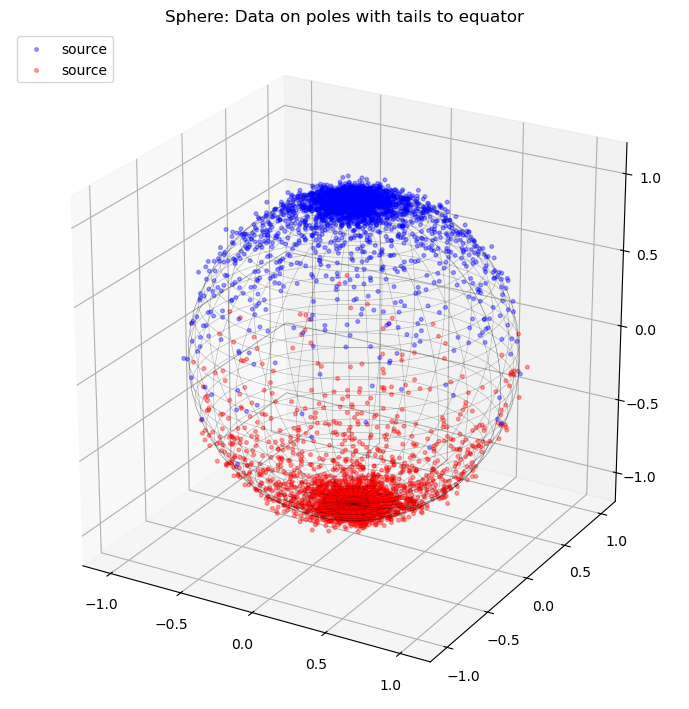

In [63]:
sphere_x0, sphere_x1 = sample_sphere_north_south_with_tails(
    n=3500,
    core_sigma=0.14,
    tail_sigma=0.62,
    tail_frac=0.42,
    thickness_sigma=0.03,
    seed=17,
)

fig = plt.figure(figsize=(8.6, 7.2))
ax = fig.add_subplot(111, projection="3d")
plot_sphere(ax, sphere_x0, sphere_x1)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [64]:
samples = torch.cat([
    torch.tensor(sphere_x0, dtype=torch.float32),
    torch.tensor(sphere_x1, dtype=torch.float32),
], dim=0)

metric = PaperRBFMetricSimple(
    ambient_dim=3,
    n_centers=60,
    kappa=1.0,
    alpha=1.0,
    eps=1e-3,
)

fit_result = metric.fit(
    samples,
    steps=300,
    lr=1e-2,
    batch_size=512,
    seed=17,
)

print(fit_result)

[paper-rbf-simple] step 30/300 loss=0.055452
[paper-rbf-simple] step 60/300 loss=0.046065
[paper-rbf-simple] step 90/300 loss=0.053429
[paper-rbf-simple] step 120/300 loss=0.048356
[paper-rbf-simple] step 150/300 loss=0.049169
[paper-rbf-simple] step 180/300 loss=0.051660
[paper-rbf-simple] step 210/300 loss=0.046773
[paper-rbf-simple] step 240/300 loss=0.054793
[paper-rbf-simple] step 270/300 loss=0.045451
[paper-rbf-simple] step 300/300 loss=0.049209
PaperRBFFitResult(final_loss=0.0492093451321125, n_centers=60, n_steps=300)


In [65]:
extent = 1.4
n_cloud = 12000
rng = np.random.default_rng(0)

cloud = rng.uniform(-extent, extent, size=(n_cloud * 3, 3))
rad = np.linalg.norm(cloud, axis=1)
cloud = cloud[rad <= extent]
cloud = cloud[:n_cloud]

cloud_t = torch.from_numpy(cloud).to(dtype=metric.C.dtype, device=metric.C.device)

with torch.no_grad():
    g_cloud = metric.metric_weight(cloud_t).cpu().numpy().ravel()



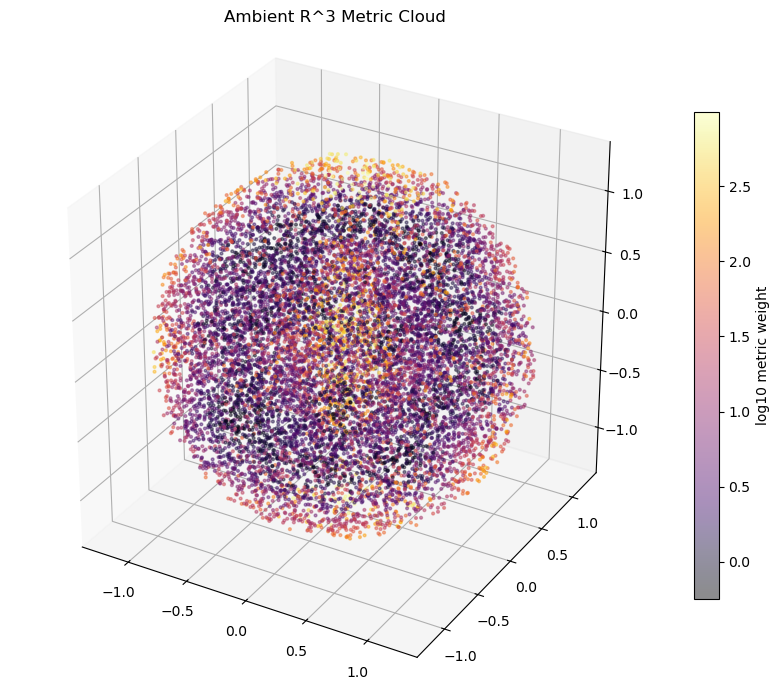

In [66]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

p = ax.scatter(
    cloud[:, 0],
    cloud[:, 1],
    cloud[:, 2],
    c=np.log10(g_cloud),
    s=4,
    alpha=0.45,
    cmap="inferno",
)

fig.colorbar(p, ax=ax, shrink=0.75, pad=0.04, label="log10 metric weight")

ax.set_title("Ambient R^3 Metric Cloud")
ax.set_xlim([-extent, extent])
ax.set_ylim([-extent, extent])
ax.set_zlim([-extent, extent])
ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()



In [67]:
xs = np.linspace(-extent, extent, 320)
zs = np.linspace(-extent, extent, 320)
xx, zz = np.meshgrid(xs, zs)
yy = np.zeros_like(xx)

plane_pts = np.stack([xx.ravel(), yy.ravel(), zz.ravel()], axis=1)
plane_t = torch.from_numpy(plane_pts).to(dtype=metric.C.dtype, device=metric.C.device)

with torch.no_grad():
    g_plane = metric.metric_weight(plane_t).cpu().numpy().reshape(xx.shape)


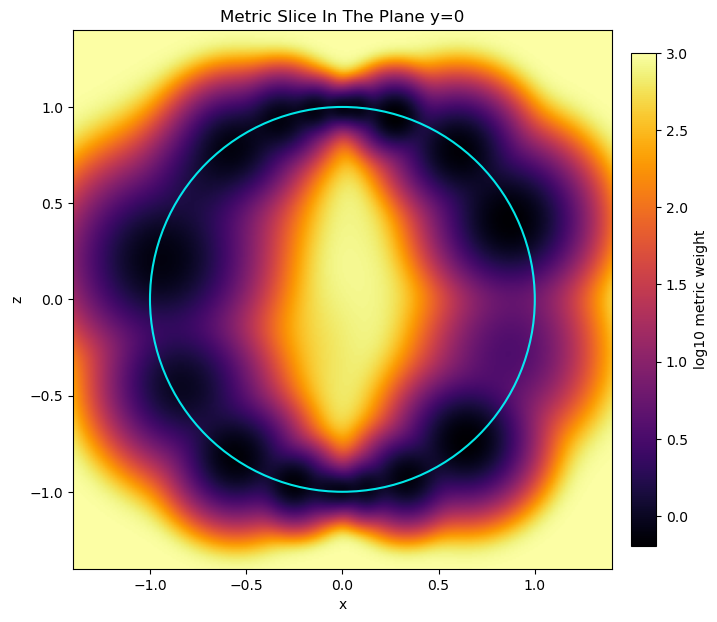

In [68]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))

im = ax.imshow(
    np.log10(g_plane),
    origin="lower",
    extent=[-extent, extent, -extent, extent],
    cmap="inferno",
    aspect="equal",
)
fig.colorbar(im, ax=ax, shrink=0.85, pad=0.03, label="log10 metric weight")

circle = plt.Circle((0.0, 0.0), 1.0, color="cyan", fill=False, linewidth=1.5, alpha=0.9)
ax.add_patch(circle)

ax.set_xlabel("x")
ax.set_ylabel("z")
ax.set_title("Metric Slice In The Plane y=0")

plt.tight_layout()
plt.show()


## Torus Metric

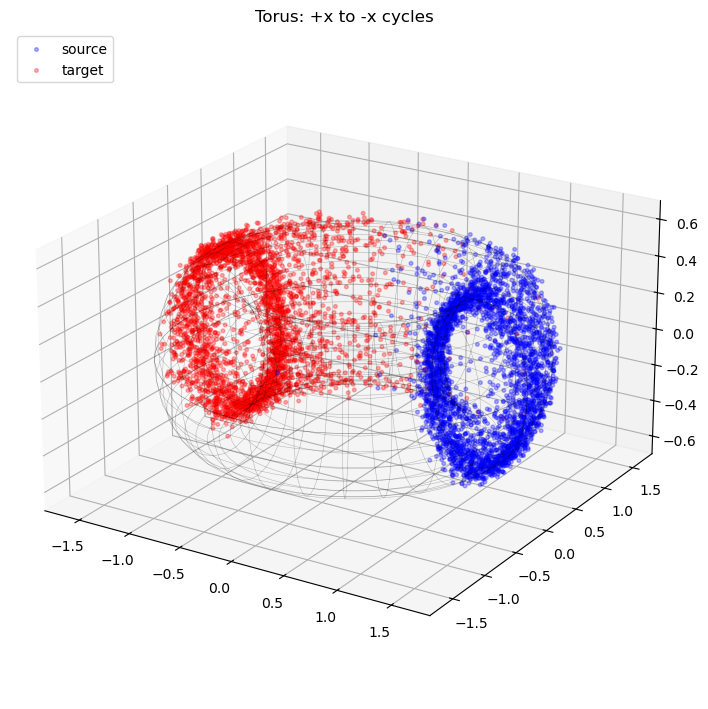

In [69]:
torus_x0, torus_x1 = sample_torus_posnegx(
    n=3500,
    sigma_u_core=0.12,
    sigma_u_tail=0.72,
    tail_frac=0.40,
    sigma_v_pair=0.06,
    thickness_sigma=0.03,
    R=1.2,
    r=0.45,
    seed=30,
)

fig = plt.figure(figsize=(8.6, 7.2))
ax = fig.add_subplot(111, projection="3d")
plot_torus(ax, torus_x0, torus_x1, R=1.2, r=0.45)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [70]:
samplest = torch.cat([
    torch.tensor(torus_x0, dtype=torch.float32),
    torch.tensor(torus_x1, dtype=torch.float32),
], dim=0)

metrict = PaperRBFMetricSimple(
    ambient_dim=3,
    n_centers=60,
    kappa=1.0,
    alpha=1.0,
    eps=1e-3,
)

fit_resultt = metrict.fit(
    samplest,
    steps=300,
    lr=1e-2,
    batch_size=512,
    seed=17,
)

print(fit_resultt)
metrict.save("torus_paper_rbf_metric.pt")

[paper-rbf-simple] step 30/300 loss=0.076074
[paper-rbf-simple] step 60/300 loss=0.065509
[paper-rbf-simple] step 90/300 loss=0.068900
[paper-rbf-simple] step 120/300 loss=0.069379
[paper-rbf-simple] step 150/300 loss=0.084070
[paper-rbf-simple] step 180/300 loss=0.085168
[paper-rbf-simple] step 210/300 loss=0.073169
[paper-rbf-simple] step 240/300 loss=0.077037
[paper-rbf-simple] step 270/300 loss=0.072378
[paper-rbf-simple] step 300/300 loss=0.073401
PaperRBFFitResult(final_loss=0.07340104877948761, n_centers=60, n_steps=300)


In [71]:
R = 1.2
r = 0.45
extent = R + r + 0.3
n_cloud = 14000
rng = np.random.default_rng(0)

cloud = rng.uniform(-extent, extent, size=(n_cloud * 3, 3))
cloud = cloud[np.abs(cloud[:, 2]) <= r + 0.6]
cloud = cloud[:n_cloud]

cloud_t = torch.from_numpy(cloud).to(dtype=metric.C.dtype, device=metric.C.device)

with torch.no_grad():
    g_cloud = metrict.metric_weight(cloud_t).cpu().numpy().ravel()


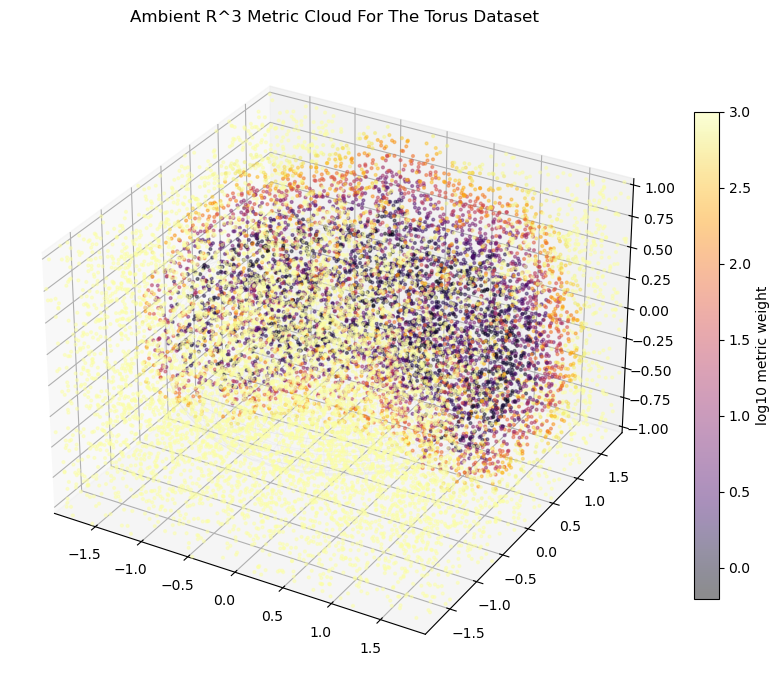

In [72]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

uu = np.linspace(0.0, 2.0 * np.pi, 50)
vv = np.linspace(0.0, 2.0 * np.pi, 30)
U, V = np.meshgrid(uu, vv)
X = (R + r * np.cos(V)) * np.cos(U)
Y = (R + r * np.cos(V)) * np.sin(U)
Z = r * np.sin(V)

ax.plot_wireframe(X, Y, Z, color="lightgray", linewidth=0.5, alpha=0.2)

p = ax.scatter(
    cloud[:, 0],
    cloud[:, 1],
    cloud[:, 2],
    c=np.log10(g_cloud),
    s=4,
    alpha=0.45,
    cmap="inferno",
)

fig.colorbar(p, ax=ax, shrink=0.75, pad=0.04, label="log10 metric weight")

ax.set_title("Ambient R^3 Metric Cloud For The Torus Dataset")
ax.set_xlim([-extent, extent])
ax.set_ylim([-extent, extent])
ax.set_zlim([-r - 0.6, r + 0.6])
ax.set_box_aspect([1, 1, 0.7])

plt.tight_layout()
plt.show()


In [73]:
xs = np.linspace(-extent, extent, 320)
zs = np.linspace(-extent, extent, 320)
xx, zz = np.meshgrid(xs, zs)
yy = np.zeros_like(xx)

plane_pts = np.stack([xx.ravel(), yy.ravel(), zz.ravel()], axis=1)
plane_t = torch.from_numpy(plane_pts).to(dtype=metrict.C.dtype, device=metrict.C.device)

with torch.no_grad():
    g_plane = metrict.metric_weight(plane_t).cpu().numpy().reshape(xx.shape)


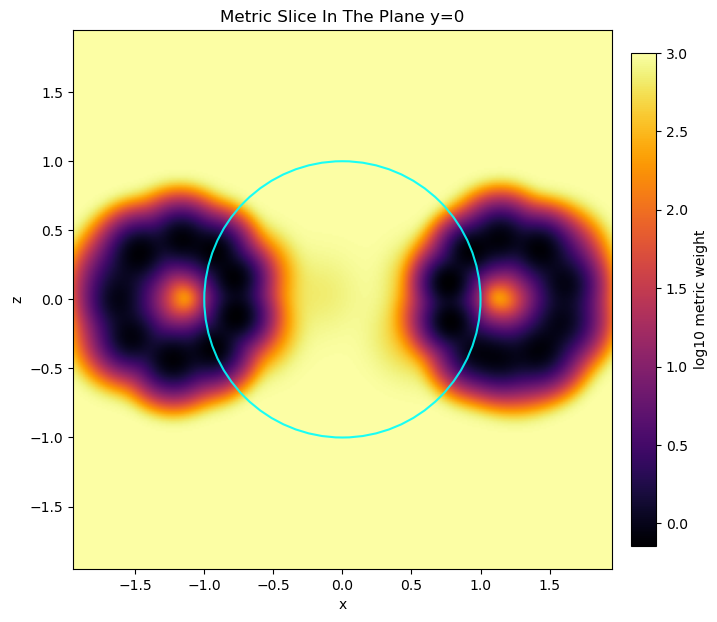

In [74]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))

im = ax.imshow(
    np.log10(g_plane),
    origin="lower",
    extent=[-extent, extent, -extent, extent],
    cmap="inferno",
    aspect="equal",
)
fig.colorbar(im, ax=ax, shrink=0.85, pad=0.03, label="log10 metric weight")

circle = plt.Circle((0.0, 0.0), 1.0, color="cyan", fill=False, linewidth=1.5, alpha=0.9)
ax.add_patch(circle)

ax.set_xlabel("x")
ax.set_ylabel("z")
ax.set_title("Metric Slice In The Plane y=0")

plt.tight_layout()
plt.show()


## Genus 2 Metric

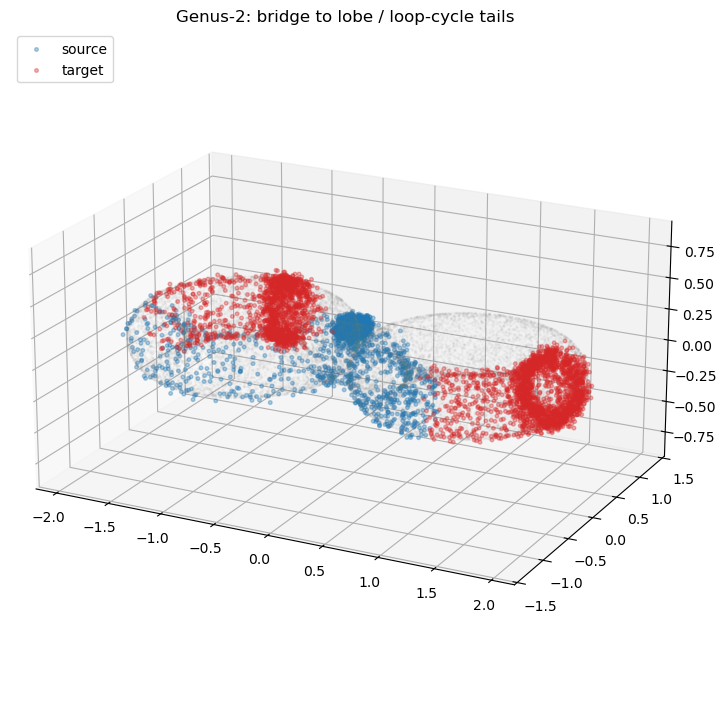

In [75]:
genus2_x0, genus2_x1, genus2_bg = sample_genus2_data(
    n=3500,
    a=1.05,
    loop_R=0.75,
    tube_r=0.24,
    thickness_sigma=0.03,
    seed=46,
)

fig = plt.figure(figsize=(8.6, 7.2))
ax = fig.add_subplot(111, projection="3d")
plot_genus2(ax, genus2_x0, genus2_x1, genus2_bg)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [76]:
samplesgen2 = torch.cat([
    torch.tensor(genus2_x0, dtype=torch.float32),
    torch.tensor(genus2_x1, dtype=torch.float32),
], dim=0)

metricgen2 = PaperRBFMetricSimple(
    ambient_dim=3,
    n_centers=60,
    kappa=1.0,
    alpha=1.0,
    eps=1e-3,
)

fit_resultgen2 = metricgen2.fit(
    samplesgen2,
    steps=300,
    lr=1e-2,
    batch_size=512,
    seed=17,
)

print(fit_resultgen2)
metricgen2.save("genus2_paper_rbf_metric.pt")

[paper-rbf-simple] step 30/300 loss=0.105150
[paper-rbf-simple] step 60/300 loss=0.098997
[paper-rbf-simple] step 90/300 loss=0.099168
[paper-rbf-simple] step 120/300 loss=0.085344
[paper-rbf-simple] step 150/300 loss=0.088579
[paper-rbf-simple] step 180/300 loss=0.097292
[paper-rbf-simple] step 210/300 loss=0.086412
[paper-rbf-simple] step 240/300 loss=0.090123
[paper-rbf-simple] step 270/300 loss=0.091773
[paper-rbf-simple] step 300/300 loss=0.099937
PaperRBFFitResult(final_loss=0.09993734955787659, n_centers=60, n_steps=300)


In [77]:
extent_x = 2.3
extent_y = 1.6
extent_z = 1.0
n_cloud = 16000
rng = np.random.default_rng(0)

cloud = np.column_stack([
    rng.uniform(-extent_x, extent_x, size=n_cloud * 3),
    rng.uniform(-extent_y, extent_y, size=n_cloud * 3),
    rng.uniform(-extent_z, extent_z, size=n_cloud * 3),
])

cloud = cloud[:n_cloud]

cloud_t = torch.from_numpy(cloud).to(dtype=metricgen2.C.dtype, device=metricgen2.C.device)

with torch.no_grad():
    g_cloud = metricgen2.metric_weight(cloud_t).cpu().numpy().ravel()


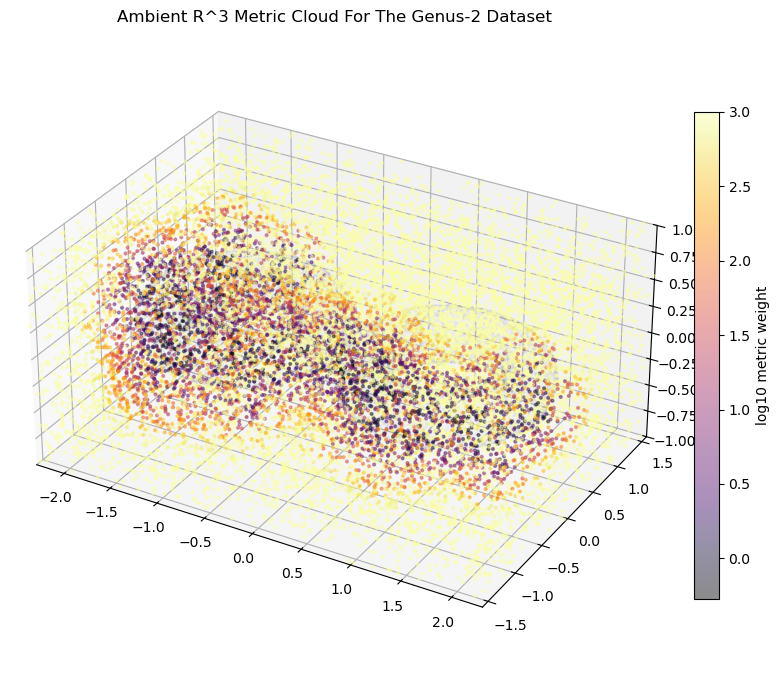

In [78]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    genus2_bg[:, 0],
    genus2_bg[:, 1],
    genus2_bg[:, 2],
    s=1,
    alpha=0.03,
    c="gray",
)

p = ax.scatter(
    cloud[:, 0],
    cloud[:, 1],
    cloud[:, 2],
    c=np.log10(g_cloud),
    s=4,
    alpha=0.45,
    cmap="inferno",
)

fig.colorbar(p, ax=ax, shrink=0.75, pad=0.04, label="log10 metric weight")

ax.set_title("Ambient R^3 Metric Cloud For The Genus-2 Dataset")
ax.set_xlim([-extent_x, extent_x])
ax.set_ylim([-extent_y, extent_y])
ax.set_zlim([-extent_z, extent_z])
ax.set_box_aspect([1.5, 1.05, 0.72])

plt.tight_layout()
plt.show()


In [79]:
xs = np.linspace(-extent_x, extent_x, 360)
zs = np.linspace(-extent_z, extent_z, 240)
xx, zz = np.meshgrid(xs, zs)
yy = np.zeros_like(xx)

plane_pts = np.stack([xx.ravel(), yy.ravel(), zz.ravel()], axis=1)
plane_t = torch.from_numpy(plane_pts).to(dtype=metricgen2.C.dtype, device=metricgen2.C.device)

with torch.no_grad():
    g_plane = metricgen2.metric_weight(plane_t).cpu().numpy().reshape(xx.shape)

slice_band = np.abs(genus2_bg[:, 1]) < 0.03
genus2_xz_slice = genus2_bg[slice_band][:, [0, 2]]


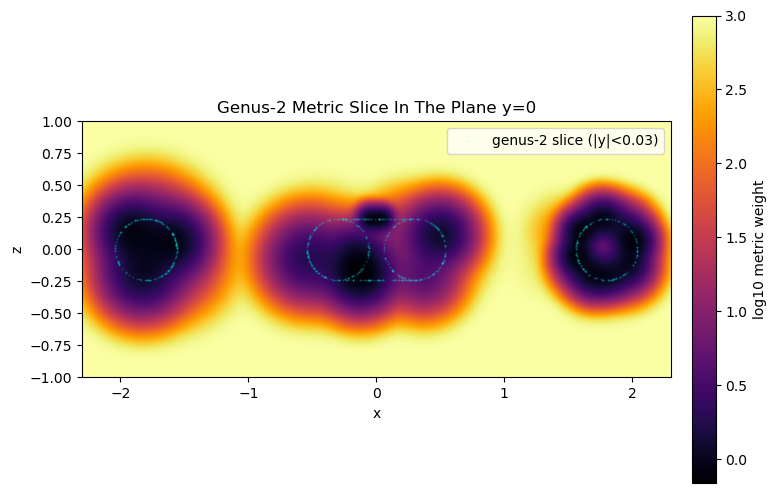

In [80]:
fig, ax = plt.subplots(figsize=(8.2, 5.8))

im = ax.imshow(
    np.log10(g_plane),
    origin="lower",
    extent=[-extent_x, extent_x, -extent_z, extent_z],
    cmap="inferno",
    aspect="equal",
)
fig.colorbar(im, ax=ax, shrink=0.85, pad=0.03, label="log10 metric weight")

if genus2_xz_slice.shape[0] > 0:
    ax.scatter(
        genus2_xz_slice[:, 0],
        genus2_xz_slice[:, 1],
        s=2.0,
        alpha=0.22,
        c="cyan",
        linewidths=0.0,
        label="genus-2 slice (|y|<0.03)",
    )
    ax.legend(loc="upper right")

ax.set_xlabel("x")
ax.set_ylabel("z")
ax.set_title("Genus-2 Metric Slice In The Plane y=0")

plt.tight_layout()
plt.show()


## Neural Network Model

In this section, we are going to implement the neural network models that will be used for the geodesic network and also for the flow matching network. There are three steps that we are going to follow:
- Training the Interpolant Network, using the metric
- Training the Flow Matching to model the interpolants
- Use the Flow Matching Network to Integrate forward the flow on the manifold

### Metric Loader and Velocity Computation

In [81]:
# For introducing the coupled samples, we include

@dataclass
class CoupledSamples:
    x0: torch.Tensor
    x1: torch.Tensor

# We need to load the metric from before

def load_metric(ckpt_path, device):
    return PaperRBFMetricSimple.load(ckpt_path, device=device)

In [82]:
# We need to be able to compute the velocity along a given path

def phi_and_path_derivative(
    phi_net,
    x0,
    x1,
    t,
):
    
    inp = torch.cat([x0, x1, t], dim=1)
    phi = phi_net(inp)

    phi_dot_cols = []

    for k in range(phi.shape[1]):
        grad_k = torch.autograd.grad(
            phi[:, k].sum(), t, create_graph=True, retain_graph=True
        )[0]
        phi_dot_cols.append(grad_k)
    phi_dot = torch.cat(phi_dot_cols, dim=1)

    xt = (1.0 - t) * x0 + t * x1 + t * (1.0 - t) * phi
    xt_dot = x1 - x0 + (1.0 - 2.0 * t) * phi + t * (1.0 - t) * phi_dot
    return phi, xt, xt_dot

### Base Network

In [83]:
# We want a simple class that gives a neural network, such that hyperparameter optimization is simple. 
# We are going to make our networks inherit all of its qualities

class MLP(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim,
        hidden_dim,
        hidden_layers,
    ):
        super().__init__()

        layers: list[nn.Module] = [nn.Linear(in_dim, hidden_dim), nn.ReLU()]
    
        for _ in range(hidden_layers-1):
            layers.extend([nn.Linear(hidden_dim, hidden_dim), nn.ReLU()])
        layers.append(nn.Linear(hidden_dim, out_dim))
    
        self.net = nn.Sequential(*layers)
        self.hidden_dim = hidden_dim
        self.hidden_layers = hidden_layers

    def forward(self, x):
        return self.net(x)
    

### Interpolant Network

In [84]:
# Let us initialize the interpolant network. This implements MLP, so it inherits all of its functionalities

class InterpolantNet(MLP):

    def __init__(
        self,
        ambient_dim,
        hidden_dim,
        hidden_layers,
    ):
        super().__init__(
            in_dim = 2*ambient_dim + 1,
            out_dim = ambient_dim,
            hidden_dim = hidden_dim,
            hidden_layers = hidden_layers
        )
    

In [85]:
# Train the Interpolant Neural Network

def train_interpolant(
    phi_net,
    coupled,
    metric,
    eps,
    steps,
    batch_size,
    lr,
    log,
):
    opt = optim.Adam(phi_net.parameters(), lr = lr)
    n = coupled.x0.shape[0]

    for step in range(steps):

        idx = torch.randint(0, n, (min(batch_size, n),), device=coupled.x0.device)
        x0 = coupled.x0[idx]
        x1 = coupled.x1[idx]
        t = torch.rand(x0.shape[0], 1, dtype=torch.float32,device=x0.device, requires_grad=True)
        _, xt, xt_dot = phi_and_path_derivative(phi_net, x0, x1, t)
        g = metric.metric_weight(xt)
        loss = (xt_dot.pow(2).sum(dim = 1, keepdim=True)*g).mean()

        opt.zero_grad()
        loss.backward()
        opt.step()

        if (step + 1) % log == 0:
            print(f"[phi] step {step + 1}/{steps} loss={loss.item():.6f}")

In [86]:
# We want to be able to evaluate the interpolant network tra

def evaluate_interpolant_traj(
    phi_net,
    x0,
    x1,
    n_steps,
):
    ts = torch.linspace(0.0, 1.0, n_steps, device = x0.device)
    traj = []
    phi_net.eval()

    for t_val in ts:
        for t_val in ts:
            t = torch.full((x0.shape[0], 1), float(t_val),dtype=torch.float32, device=x0.device, requires_grad=True)
            with torch.enable_grad():
                _, xt, _ = phi_and_path_derivative(phi_net, x0, x1, t)
            traj.append(xt.detach())
    return torch.stack(traj, dim=1)

In [87]:
# Trajectory Inference: We want to infer trajectories without having to call the entire network that computes dphi, using grad

def evaluate_interpolant_positions(phi_net, x0, x1, n_steps):
    ts = torch.linspace(0.0, 1.0, n_steps, device=x0.device)
    traj = []

    phi_net.eval()
    with torch.no_grad():
        for t_val in ts:
            t = torch.full((x0.shape[0], 1), float(t_val), dtype=torch.float32, device=x0.device)
            phi = phi_net(torch.cat([x0, x1, t], dim=1))
            xt = (1.0 - t) * x0 + t * x1 + t * (1.0 - t) * phi
            traj.append(xt)

    return torch.stack(traj, dim=1)


### Velocity Network

In [88]:
# Write a Velocity Net Class. This implements MLP, so it inherits all of its functionalities

class VelocityNet(MLP):

    def __init__(
        self,
        ambient_dim,
        hidden_dim,
        hidden_layers,
    ):
        super().__init__(
            in_dim = ambient_dim + 1,
            out_dim = ambient_dim,
            hidden_dim = hidden_dim,
            hidden_layers = hidden_layers,
        )

In [89]:
# Training Fucntion for the velocity 

def train_velocity(
    v_net,
    phi_net,
    coupled,
    metric,
    eps,
    steps,
    batch_size,
    lr,
    log,
):
    opt = optim.Adam(v_net.parameters(), lr=lr)
    n = coupled.x0.shape[0]
    phi_net.eval()

    for step in range(steps):
        idx = torch.randint(0, n, (min(batch_size, n),), device=coupled.x0.device)
        x0 = coupled.x0[idx]
        x1 = coupled.x1[idx]
        t = torch.rand(x0.shape[0], 1, dtype=torch.float32, device=x0.device, requires_grad=True)

        with torch.enable_grad():
            _, xt, xt_dot = phi_and_path_derivative(phi_net, x0, x1, t)

        v_pred = v_net(torch.cat([xt.detach(), t.detach()], dim=1))
        g = metric.metric_weight(xt.detach())
        loss = ((v_pred - xt_dot.detach()).pow(2).sum(dim=1, keepdim=True) * g).mean()

        opt.zero_grad()
        loss.backward()
        opt.step()

        if (step + 1) % log == 0:
            print(f"[v] step {step + 1}/{steps} loss={loss.item():.6f}")

In [90]:
# Integrating the Velocity forward

def integrate_flow(
    v_net,
    x_init,
    n_steps,
):
    dt = 1.0 / n_steps
    x = x_init.clone()
    traj = [x.clone()]

    v_net.eval()
    with torch.no_grad():
        for i in range(n_steps):
            t_val = (i + 0.5) * dt
            t = torch.full((x.shape[0], 1), float(t_val), dtype=torch.float32, device=x.device)
            v = v_net(torch.cat([x, t], dim=1))
            x = x + dt * v
            traj.append(x.clone())

    return x, torch.stack(traj, dim=1)

## Save and Load the Models

In [91]:
def save_network(module: nn.Module, path: str) -> None:
    torch.save(module.state_dict(), path)


def load_network(module: nn.Module, path: str, map_location: str | torch.device | None = None) -> nn.Module:
    state = torch.load(path, map_location=map_location or "cpu")
    module.load_state_dict(state)
    return module

## Running the Models

In [92]:
# Running the Training incorporates multiple steps here

def run_training(
    x0: torch.Tensor,
    x1: torch.Tensor,
    metric_ckpt_path: str,
    phi_hidden_dim: int = 128,
    phi_hidden_layers: int = 2,
    v_hidden_dim: int = 128,
    v_hidden_layers: int = 2,
    phi_steps: int = 1000,
    v_steps: int = 1000,
    batch_size: int = 256,
    phi_lr: float = 1e-3,
    v_lr: float = 1e-3,
    ode_steps: int = 100,
    log: int = 500,
    device: torch.device | None = None,
) -> dict[str, object]:
    """End-to-end helper for notebook usage.

    Returns a dictionary containing the metric, networks, transported endpoints,
    and full trajectory tensor.
    """
    if device is None:
        device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

    x0 = x0.to(device=device, dtype=torch.float32)
    x1 = x1.to(device=device, dtype=torch.float32)
    coupled = CoupledSamples(x0=x0, x1=x1)

    metric = load_metric(ckpt_path=metric_ckpt_path, device=device)
    # Keep metric tensors aligned with training tensors.
    if hasattr(metric, "C"):
        metric.C = metric.C.to(device=device, dtype=x0.dtype)
    if hasattr(metric, "lamda"):
        metric.lamda = metric.lamda.to(device=device, dtype=x0.dtype)
    if hasattr(metric, "W"):
        metric.W = nn.Parameter(metric.W.to(device=device, dtype=x0.dtype), requires_grad=False)

    ambient_dim = x0.shape[1]
    phi_net = InterpolantNet(
        ambient_dim=ambient_dim,
        hidden_dim=phi_hidden_dim,
        hidden_layers=phi_hidden_layers,
    ).to(device)
    v_net = VelocityNet(
        ambient_dim=ambient_dim,
        hidden_dim=v_hidden_dim,
        hidden_layers=v_hidden_layers,
    ).to(device)

    train_interpolant(
        phi_net=phi_net,
        coupled=coupled,
        metric=metric,
        eps=0.0,
        steps=phi_steps,
        batch_size=batch_size,
        lr=phi_lr,
        log=log,
    )

    print("Interpolant Training Done")

    train_velocity(
        v_net=v_net,
        phi_net=phi_net,
        coupled=coupled,
        metric=metric,
        eps=0.0,
        steps=v_steps,
        batch_size=batch_size,
        lr=v_lr,
        log=log,
    )

    print("Velocity Net Training Done")
    
    xT, traj = integrate_flow(v_net=v_net, x_init=x0, n_steps=ode_steps)

    print("Flow Integrated")
    
    n_interp_plot = 64
    idx = torch.randperm(x0.shape[0], device=x0.device)[:n_interp_plot]
    
    interp_traj = evaluate_interpolant_positions(
        phi_net=phi_net,
        x0=x0[idx],
        x1=x1[idx],
        n_steps=ode_steps + 1,
    )


    print("Trajectories Acquired")

    return {
        "metric": metric,
        "phi_net": phi_net,
        "v_net": v_net,
        "x0": x0,
        "x1": x1,
        "xT": xT,
        "traj": traj,
        "interp_traj": interp_traj,
        "coupled": coupled,
    }
    

### Plotting Training Results

In [93]:
def plot_training_result(
    result: dict[str, object],
    n_traj: int = 40,
    title_prefix: str = "",
) -> None:
    import numpy as np
    import matplotlib.pyplot as plt

    x0 = result["x0"].detach().cpu().numpy()
    x1 = result["x1"].detach().cpu().numpy()
    xT = result["xT"].detach().cpu().numpy()
    traj = result["traj"].detach().cpu().numpy()
    interp_traj = result["interp_traj"].detach().cpu().numpy()

    n = traj.shape[0]
    choose = np.random.default_rng(0).choice(n_traj, size=min(n_traj, n), replace=False)
    
    all_pts = np.vstack([x0, x1, xT, traj.reshape(-1, traj.shape[-1]), interp_traj.reshape(-1, interp_traj.shape[-1])])
    mins = all_pts.min(axis=0)
    maxs = all_pts.max(axis=0)
    center = 0.5 * (mins + maxs)
    radius = 0.55 * np.max(maxs - mins)
    radius = max(radius, 1e-3)

    fig = plt.figure(figsize=(11.5, 5.2))

    ax1 = fig.add_subplot(121, projection="3d")
    ax1.scatter(x0[:, 0], x0[:, 1], x0[:, 2], s=8, alpha=0.30, c="#1f77b4", label="source")
    ax1.scatter(x1[:, 0], x1[:, 1], x1[:, 2], s=8, alpha=0.30, c="#d62728", label="target")
    ax1.set_title(f"{title_prefix}Data".strip())
    ax1.legend(loc="upper left")

    ax2 = fig.add_subplot(122, projection="3d")
    for i in choose:
        ax2.plot(traj[i, :, 0], traj[i, :, 1], traj[i, :, 2], alpha=0.75, lw=1.0, c="#7c3aed")
    ax2.scatter(xT[:, 0], xT[:, 1], xT[:, 2], s=8, alpha=0.28, c="#7c3aed", label="flow end")
    ax2.scatter(x1[:, 0], x1[:, 1], x1[:, 2], s=8, alpha=0.18, c="#d62728", label="target")
    ax2.set_title(f"{title_prefix}Flow Result".strip())
    ax2.legend(loc="upper left")

    for ax in [ax1, ax2]:
        ax.set_xlim([center[0] - radius, center[0] + radius])
        ax.set_ylim([center[1] - radius, center[1] + radius])
        ax.set_zlim([center[2] - radius, center[2] + radius])
        ax.set_box_aspect([1, 1, 1])
        ax.view_init(elev=22, azim=-60)

    plt.tight_layout()
    plt.show()


def save_training_gif(
    result: dict[str, object],
    out_path: str,
    max_points: int = 800,
    fps: int = 16,
    title_prefix: str = "",
) -> None:
    

    x1 = result["x1"].detach().cpu().numpy()
    traj = result["traj"].detach().cpu().numpy()

    n = traj.shape[0]
    rng = np.random.default_rng(0)
    choose = rng.choice(n, size=min(max_points, n), replace=False)
    traj = traj[choose]

    all_pts = np.vstack([traj.reshape(-1, traj.shape[-1]), x1])
    mins = all_pts.min(axis=0)
    maxs = all_pts.max(axis=0)
    center = 0.5 * (mins + maxs)
    radius = 0.55 * np.max(maxs - mins)
    radius = max(radius, 1e-3)

    fig = plt.figure(figsize=(7.2, 6.6))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_xlim([center[0] - radius, center[0] + radius])
    ax.set_ylim([center[1] - radius, center[1] + radius])
    ax.set_zlim([center[2] - radius, center[2] + radius])
    ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=22, azim=-60)

    ax.scatter(x1[:, 0], x1[:, 1], x1[:, 2], s=6, alpha=0.10, c="#d62728", label="target")
    scat = ax.scatter([], [], [], s=8, alpha=0.55, c="#7c3aed", label="transport")
    ax.legend(loc="upper left")

    n_frames = traj.shape[1]

    def update(frame: int):
        pts = traj[:, frame, :]
        scat._offsets3d = (pts[:, 0], pts[:, 1], pts[:, 2])
        t_val = frame / max(1, n_frames - 1)
        ax.set_title(f"{title_prefix}Flow Transport  t={t_val:.2f}".strip())
        return (scat,)

    anim = FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=False)
    anim.save(out_path, writer=PillowWriter(fps=fps))
    plt.close(fig)


### Sphere Run

In [110]:
# ----------------------------
# 1. Setup
# ----------------------------
METRIC_PATH = "sphere_paper_rbf_metric.pt"   # <-- change if needed

torch.manual_seed(0)
np.random.seed(0)

# ----------------------------
# 2. Generate small sphere dataset
# ----------------------------
x0, x1 = sample_sphere_north_south_with_tails(
    n=4000,
    core_sigma=0.14,
    tail_sigma=0.62,
    tail_frac=0.42,
    thickness_sigma=0.03,
    seed=17,
)

resultsphere = run_training(
    x0= torch.tensor(x0),
    x1= torch.tensor(x1),
    metric_ckpt_path="sphere_paper_rbf_metric.pt",
    phi_hidden_dim=256,
    phi_hidden_layers=6,
    v_hidden_dim=256,
    v_hidden_layers=6,
    phi_steps=2000,
    v_steps=2000,
    batch_size=256,
    phi_lr=1e-3,
    v_lr=1e-3,
    ode_steps=150,
    log=500,
    device=device,
)


[phi] step 500/2000 loss=21.719177
[phi] step 1000/2000 loss=11.393227
[phi] step 1500/2000 loss=10.360221
[phi] step 2000/2000 loss=10.420456
Interpolant Training Done
[v] step 500/2000 loss=0.525903
[v] step 1000/2000 loss=0.296826
[v] step 1500/2000 loss=0.359361
[v] step 2000/2000 loss=0.313710
Velocity Net Training Done
Flow Integrated
Trajectories Acquired


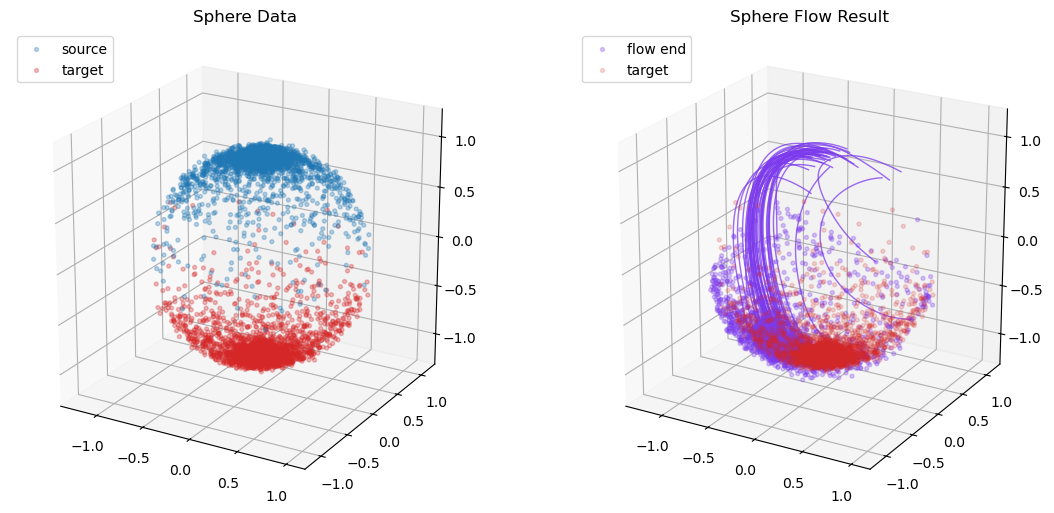

In [111]:
plot_training_result(resultsphere, n_traj=40, title_prefix="Sphere ")

In [96]:
save_training_gif(
    resultsphere,
    out_path="sphere_run.gif",
    max_points=400,
    fps=9,
    title_prefix="Sphere ",
)

### Torus Run

In [119]:
# ----------------------------
# 1. Setup
# ----------------------------
METRIC_PATH = "torus_paper_rbf_metric.pt"   # <-- change if needed

torch.manual_seed(0)
np.random.seed(0)

# ----------------------------
# 2. Generate torus dataset
# ----------------------------
x0, x1 = sample_torus_posnegx(
    n=4000,
    sigma_u_core=0.12,
    sigma_u_tail=0.72,
    tail_frac=0.40,
    sigma_v_pair=0.06,
    thickness_sigma=0.03,
    R=1.2,
    r=0.45,
    seed=30,
)

# ----------------------------
# 3. Train
# ----------------------------
resulttorus = run_training(
    x0=torch.tensor(x0),
    x1=torch.tensor(x1),
    metric_ckpt_path=METRIC_PATH,
    phi_hidden_dim=256,
    phi_hidden_layers=6,
    v_hidden_dim=256,
    v_hidden_layers=6,
    phi_steps=4000,
    v_steps=4000,
    batch_size=256,
    phi_lr=1e-4,
    v_lr=1e-4,
    ode_steps=150,
    log=500,
    device=device,
)


[phi] step 500/4000 loss=13.632976
[phi] step 1000/4000 loss=11.075035
[phi] step 1500/4000 loss=10.718537
[phi] step 2000/4000 loss=10.492982
[phi] step 2500/4000 loss=11.437578
[phi] step 3000/4000 loss=11.086625
[phi] step 3500/4000 loss=11.373764
[phi] step 4000/4000 loss=11.376868
Interpolant Training Done
[v] step 500/4000 loss=1.060184
[v] step 1000/4000 loss=0.656721
[v] step 1500/4000 loss=0.517691
[v] step 2000/4000 loss=0.572894
[v] step 2500/4000 loss=0.368964
[v] step 3000/4000 loss=0.365083
[v] step 3500/4000 loss=0.301480
[v] step 4000/4000 loss=0.279124
Velocity Net Training Done
Flow Integrated
Trajectories Acquired


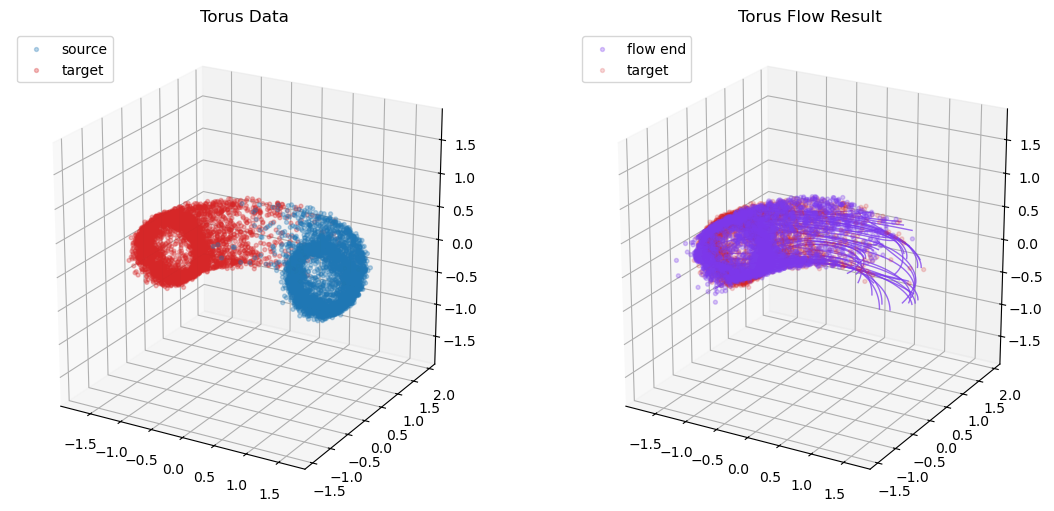

In [98]:
plot_training_result(resulttorus, n_traj=40, title_prefix="Torus ")


In [99]:
save_training_gif(
    resulttorus,
    out_path="torus_run.gif",
    max_points=800,
    fps=18,
    title_prefix="Torus ",
)


### Genus-2 Run

In [127]:
# ----------------------------
# 1. Setup
# ----------------------------
METRIC_PATH = "genus2_paper_rbf_metric.pt"   # <-- change if needed

torch.manual_seed(0)
np.random.seed(0)

# ----------------------------
# 2. Generate genus-2 dataset
# ----------------------------
x0, x1, genus2_bg = sample_genus2_data(
    n=4000,
    a=1.05,
    loop_R=0.75,
    tube_r=0.24,
    thickness_sigma=0.03,
    seed=46,
)

# ----------------------------
# 3. Train
# ----------------------------
resultgenus2 = run_training(
    x0=torch.tensor(x0),
    x1=torch.tensor(x1),
    metric_ckpt_path=METRIC_PATH,
    phi_hidden_dim=256,
    phi_hidden_layers=6,
    v_hidden_dim=256,
    v_hidden_layers=6,
    phi_steps=4000,
    v_steps=4000,
    batch_size=256,
    phi_lr=1e-4,
    v_lr=1e-4,
    ode_steps=150,
    log=500,
    device=device,
)


[phi] step 500/4000 loss=37.244263
[phi] step 1000/4000 loss=34.523117
[phi] step 1500/4000 loss=26.933615
[phi] step 2000/4000 loss=29.946142
[phi] step 2500/4000 loss=32.636604
[phi] step 3000/4000 loss=27.789616
[phi] step 3500/4000 loss=21.841385
[phi] step 4000/4000 loss=40.571220
Interpolant Training Done
[v] step 500/4000 loss=3.928507
[v] step 1000/4000 loss=1.853700
[v] step 1500/4000 loss=3.221056
[v] step 2000/4000 loss=1.942618
[v] step 2500/4000 loss=2.325104
[v] step 3000/4000 loss=2.318624
[v] step 3500/4000 loss=3.114613
[v] step 4000/4000 loss=1.880335
Velocity Net Training Done
Flow Integrated
Trajectories Acquired


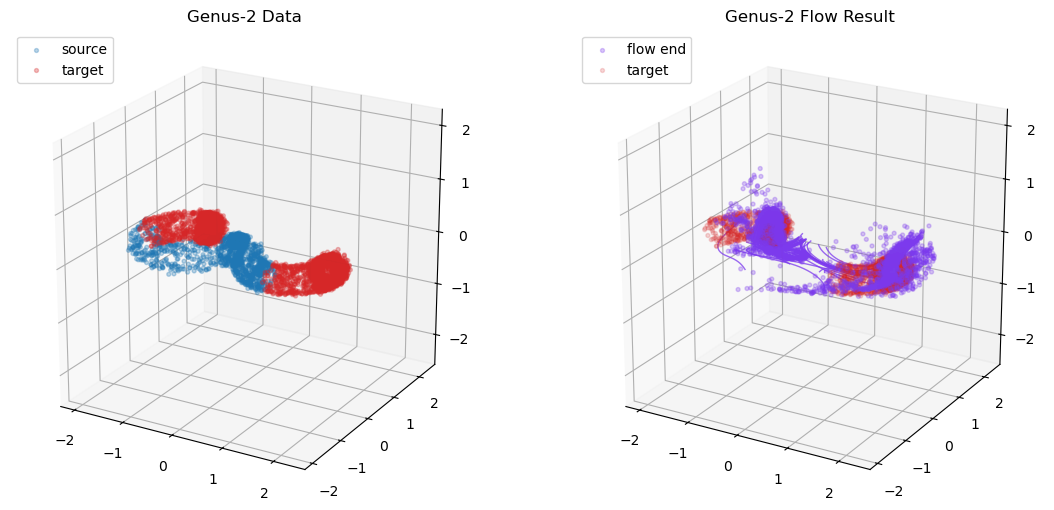

In [128]:
plot_training_result(resultgenus2, n_traj=40, title_prefix="Genus-2 ")

In [102]:
save_training_gif(
    resultgenus2,
    out_path="genus2_run.gif",
    max_points=400,
    fps=9,
    title_prefix="Genus-2 ",
)

## Part 6 Fine tune your model

* As always, automate what you can.
* You will want to use as much data as possible for this step, especially as you move toward the end of fine-tuning.

1. Fine-tune the hyperparameters using cross-validation: Treat your data transformation choices as hyperparameters, especially when you are not sure about them (e.g., if you’re not sure whether to replace missing values with zeros or with the median value, or to just drop the rows). Unless there are very few hyperparameter values to explore, prefer random search over grid search. 
2. Try Ensemble methods. Combining your best models will often produce better performance than running them individually.
3. Once you are confident about your final model, measure its performance on the testing data originally set aside to estimate the generalization error.

WARNING: Don’t tweak your model after measuring the generalization error: you would just start overfitting the test set.

# Part 6 Finetuning



We automate all of the hyperparameter tuning! The entire process of our tuning is described below. 


There are some unconventional pieces to this hyperparameter tuning:
- The final output of our network, which we want to apply to evaluation or testing data is *just* the phi_net vector field, which we use to push forward data samples.
- The only "correctness" test, one could apply to the other networks would be to compare to the real metric and the real geodesics. We could do it here, but it once again would not generalize well to more interesting problems, where we do not have access to the manifold.
- Thus, we do not optimize the metric and focus on the training loss for the interpolant network.
- The velocity network should regress to the interpolant network. Thus, the training loss is a good representative for this performance.
- Here, one could add a testing sample, push it forward and compute e.g. the Wasserstein distance of it to the corresponding final sample. We can coarsely approximate the Wasserstein distance by the distance of the two means. However, this would diagnose an issue of the interpolant network more than an issue with the velocity network, since the interpolants might simply be incorrect.

For finetuning the networks, we worked out a tuning loop that optimizes by the networks one by own. The basic algorithm is:
- tune the interpolant network phi_net
- freeze the optimal phi_net
- tune the velocity network v_net

## Auxiliary Functions

Here, we will define some auxiliary functions for fitting the data.

In [129]:
# This is our record format for one hyperparameter trial. It stores all of the hyperparameters and the evaluation scores
@dataclass
class TrialResult:
    network_type: str
    hidden_dim: int
    hidden_layers: int
    lr: float
    batch_size: int
    steps: int
    seed: int
    train_loss_last: float
    eval_score_primary: float
    eval_score_secondary: float
    ckpt_path: str | None = None

# Since, we want to ensure reproducibility of the results, we are going to fix a seed
def set_seed(seed: int) -> None:
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        
# This function ensures that all tensors in the training are float32 and can be put on my GPU
def _align_metric(metric, x_ref):
    if hasattr(metric, "C"):
        metric.C = metric.C.to(device=x_ref.device, dtype=x_ref.dtype)
    if hasattr(metric, "lamda"):
        metric.lamda = metric.lamda.to(device=x_ref.device, dtype=x_ref.dtype)
    if hasattr(metric, "W"):
        metric.W = nn.Parameter(metric.W.to(device=x_ref.device, dtype=x_ref.dtype), requires_grad=False)
    return metric

# This saves a final result of the optimization process
def _save_trial_results(records, out_path):
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump([asdict(r) for r in records], f, indent=2)
    

## Testing Metrics

For testing, we are simply using the loss functions as metrics. Initially, we also used:
- Closeness to the manifold for the interpolants
- MSE error of the pushed forward $x_0$ to its training partner $x_1$

This is why the saved data has a secondary evaluation score.



Although fruitful, we found both methods to be disingenuine, if one wanted to apply them to generic problems:
- In a generic case, we do not have a simple submanifold to compare our data to
- The MSE error does not generalize well, because the pairing is arbitrary

In [130]:
# Theses are the two loss functions of the setup evaluated on random batches

def evaluate_interpolant_loss(phi_net, coupled, metric, n_batches=8, batch_size=128, seed=0):
    set_seed(seed)
    phi_net.eval()
    losses = []
    n = coupled.x0.shape[0]
    for _ in range(n_batches):
        idx = torch.randint(0, n, (min(batch_size, n),), device=coupled.x0.device)
        x0 = coupled.x0[idx]
        x1 = coupled.x1[idx]
        t = torch.rand(x0.shape[0], 1, device=x0.device, requires_grad=True)
        with torch.enable_grad():
            _, xt, xt_dot = phi_and_path_derivative(phi_net, x0, x1, t)
            g = metric.metric_weight(xt)
            loss = (xt_dot.pow(2).sum(dim=1, keepdim=True) * g).mean()
        losses.append(float(loss.detach().cpu().item()))
    return float(np.mean(losses))

def evaluate_velocity_loss(v_net, phi_net, coupled, metric, n_batches=8, batch_size=128, seed=0):
    set_seed(seed)
    v_net.eval()
    phi_net.eval()
    losses = []
    n = coupled.x0.shape[0]
    for _ in range(n_batches):
        idx = torch.randint(0, n, (min(batch_size, n),), device=coupled.x0.device)
        x0 = coupled.x0[idx]
        x1 = coupled.x1[idx]
        t = torch.rand(x0.shape[0], 1, device=x0.device, requires_grad=True)
        with torch.enable_grad():
            _, xt, xt_dot = phi_and_path_derivative(phi_net, x0, x1, t)
        with torch.no_grad():
            v_pred = v_net(torch.cat([xt.detach(), t.detach()], dim=1))
            g = metric.metric_weight(xt.detach())
            loss = ((v_pred - xt_dot.detach()).pow(2).sum(dim=1, keepdim=True) * g).mean()
        losses.append(float(loss.detach().cpu().item()))
    return float(np.mean(losses))

## Tuning Algorithms

The tuning algorithms for the networks work identically for both networks.
\\
We initiate a sweep (grid search) over the following hyperparameters:
- hidden_dim
- hidden_layers
- learning_rate
- batch_size

in two different stages:
- a broad scan that does not allow for a long deep training (steps_short)
- a focused scan that allows the networks to nail down their search to the optimal parameters from the broad_scan (steps_long)
- there is a parameter top_k that decides on how many candidates from the broad scan will move onto the focused scan

Obviously, this has weaknesses:
- It can happen that networks struggle early in their training, have longterm generalization.
- These networks take longer to converge.


In [131]:

def tune_interpolant(
    x0,
    x1,
    metric_ckpt_path,
    hidden_dims=(32, 64, 128, 256),
    hidden_layers_list=(2, 4, 6),
    learning_rates=(1e-4, 3e-4, 1e-3),
    batch_sizes=(64, 128, 256),
    steps_short=500,
    steps_long=3000,
    top_k=4,
    eval_batches=8,
    eval_batch_size=128,
    log=100,
    seed=0,
    device=None,
    save_dir=None,
):

    # Put every thing on GPU, if possible
    if device is None:
        device = x0.device
    x0 = x0.to(device=device, dtype=torch.float32)
    x1 = x1.to(device=device, dtype=torch.float32)
    coupled = CoupledSamples(x0=x0, x1=x1)
    metric = _align_metric(load_metric(metric_ckpt_path, device), x0)
    ambient_dim = x0.shape[1]
    save_dir = Path(save_dir) if save_dir is not None else None
    if save_dir is not None:
        save_dir.mkdir(parents=True, exist_ok=True)


    # Starting the coarse run
    
    coarse_records = []
    # Initialize configurations
    configs = list(product(hidden_dims, hidden_layers_list, learning_rates, batch_sizes))\
    
    for trial_idx, (hidden_dim, hidden_layers, lr, batch_size) in enumerate(configs):

        # Initialize seeds
        trial_seed = seed + trial_idx
        set_seed(trial_seed)

        # Train network
        phi_net = InterpolantNet(ambient_dim, hidden_dim, hidden_layers).to(device)
        train_interpolant(phi_net, coupled, metric, eps=0.0, steps=steps_short, batch_size=batch_size, lr=lr, log=log)

        # Compute loss
        eval_loss = evaluate_interpolant_loss(phi_net, coupled, metric, n_batches=eval_batches, batch_size=eval_batch_size, seed=trial_seed)

        # Save Result
        ckpt_path = None
        if save_dir is not None:
            ckpt_path = str(save_dir / f"phi_coarse_{trial_idx:03d}.pt")
            save_network(phi_net, ckpt_path)
        coarse_records.append(TrialResult(
            network_type="phi",
            hidden_dim=hidden_dim,
            hidden_layers=hidden_layers,
            lr=float(lr),
            batch_size=int(batch_size),
            steps=int(steps_short),
            seed=int(trial_seed),
            train_loss_last=float(eval_loss),
            eval_score_primary=float(eval_loss),
            eval_score_secondary=0.0,
            ckpt_path=ckpt_path,
        ))

    # Determine the finalists based on the evaluation score
    coarse_records.sort(key=lambda r: r.eval_score_primary)
    finalists = coarse_records[:min(top_k, len(coarse_records))]

    # Start search for the winner
    final_records = []
    best_model = None
    best_score = float("inf")
    best_config = None
    best_ckpt = None

    # Train all of the finalists and save their results after long training
    for rank, coarse in enumerate(finalists):
        set_seed(coarse.seed)
        phi_net = InterpolantNet(ambient_dim, coarse.hidden_dim, coarse.hidden_layers).to(device)
        train_interpolant(phi_net, coupled, metric, eps=0.0, steps=steps_long, batch_size=coarse.batch_size, lr=coarse.lr, log=log)
        eval_loss = evaluate_interpolant_loss(phi_net, coupled, metric, n_batches=eval_batches, batch_size=eval_batch_size, seed=coarse.seed)
        ckpt_path = None
        if save_dir is not None:
            ckpt_path = str(save_dir / f"phi_final_{rank:02d}.pt")
            save_network(phi_net, ckpt_path)
        record = TrialResult(
            network_type="phi",
            hidden_dim=coarse.hidden_dim,
            hidden_layers=coarse.hidden_layers,
            lr=float(coarse.lr),
            batch_size=int(coarse.batch_size),
            steps=int(steps_long),
            seed=int(coarse.seed),
            train_loss_last=float(eval_loss),
            eval_score_primary=float(eval_loss),
            eval_score_secondary=0.0,
            ckpt_path=ckpt_path,
        )
        final_records.append(record)

        # Change the momentary leader
        if eval_loss < best_score:
            best_score = float(eval_loss)
            best_model = phi_net
            best_config = {
                "phi_hidden_dim": coarse.hidden_dim,
                "phi_hidden_layers": coarse.hidden_layers,
                "phi_lr": coarse.lr,
                "batch_size": coarse.batch_size,
                "phi_steps": steps_long,
            }
            best_ckpt = ckpt_path

    # Save all results
    if save_dir is not None:
        _save_trial_results(coarse_records, str(save_dir / "phi_coarse_results.json"))
        _save_trial_results(final_records, str(save_dir / "phi_final_results.json"))
        if best_model is not None:
            best_ckpt = str(save_dir / "best_phi.pt")
            save_network(best_model, best_ckpt)

    # Return best results
    return {
        "coarse_results": [asdict(r) for r in coarse_records],
        "final_results": [asdict(r) for r in sorted(final_records, key=lambda r: r.eval_score_primary)],
        "best_config": best_config,
        "best_score": best_score,
        "best_model": best_model,
        "best_ckpt_path": best_ckpt,
    }


def tune_velocity(
    x0,
    x1,
    metric_ckpt_path,
    phi_ckpt_path,
    phi_hidden_dim,
    phi_hidden_layers,
    hidden_dims=(32, 64, 128, 256),
    hidden_layers_list=(2, 4, 6),
    learning_rates=(1e-4, 3e-4, 1e-3),
    batch_sizes=(64, 128, 256),
    steps_short=800,
    steps_long=5000,
    top_k=4,
    eval_batches=8,
    eval_batch_size=128,
    eval_ode_steps=100,
    log=100,
    seed=0,
    device=None,
    save_dir=None,
):

    # Put everything on the GPU if possible
    if device is None:
        device = x0.device
    x0 = x0.to(device=device, dtype=torch.float32)
    x1 = x1.to(device=device, dtype=torch.float32)
    coupled = CoupledSamples(x0=x0, x1=x1)
    metric = _align_metric(load_metric(metric_ckpt_path, device), x0)
    ambient_dim = x0.shape[1]
    phi_net = InterpolantNet(ambient_dim, phi_hidden_dim, phi_hidden_layers).to(device)
    load_network(phi_net, phi_ckpt_path, map_location=device)
    phi_net.eval()
    save_dir = Path(save_dir) if save_dir is not None else None
    if save_dir is not None:
        save_dir.mkdir(parents=True, exist_ok=True)

    # Start the coarse run
    coarse_records = []
    configs = list(product(hidden_dims, hidden_layers_list, learning_rates, batch_sizes))
    for trial_idx, (hidden_dim, hidden_layers, lr, batch_size) in enumerate(configs):
        trial_seed = seed + trial_idx
        set_seed(trial_seed)

        # Train and evaluate the network
        v_net = VelocityNet(ambient_dim, hidden_dim, hidden_layers).to(device)
        train_velocity(v_net, phi_net, coupled, metric, eps=0.0, steps=steps_short, batch_size=batch_size, lr=lr, log=log)
        eval_loss = evaluate_velocity_loss(v_net, phi_net, coupled, metric, n_batches=eval_batches, batch_size=eval_batch_size, seed=trial_seed)

        # Collect the performance data
        ckpt_path = None
        if save_dir is not None:
            ckpt_path = str(save_dir / f"v_coarse_{trial_idx:03d}.pt")
            save_network(v_net, ckpt_path)
        coarse_records.append(TrialResult(
            network_type="v",
            hidden_dim=hidden_dim,
            hidden_layers=hidden_layers,
            lr=float(lr),
            batch_size=int(batch_size),
            steps=int(steps_short),
            seed=int(trial_seed),
            train_loss_last=float(eval_loss),
            eval_score_primary=float(eval_loss),
            eval_score_secondary=0.0,
            ckpt_path=ckpt_path,
        ))

    # Determine the finalists
    coarse_records.sort(key=lambda r: r.eval_score_primary)
    finalists = coarse_records[:min(top_k, len(coarse_records))]

    # Start the final run to determine the champion
    final_records = []
    best_model = None
    best_score = float("inf")
    best_config = None
    best_ckpt = None
    for rank, coarse in enumerate(finalists):
        set_seed(coarse.seed)
        v_net = VelocityNet(ambient_dim, coarse.hidden_dim, coarse.hidden_layers).to(device)
        train_velocity(v_net, phi_net, coupled, metric, eps=0.0, steps=steps_long, batch_size=coarse.batch_size, lr=coarse.lr, log=log)
        eval_loss = evaluate_velocity_loss(v_net, phi_net, coupled, metric, n_batches=eval_batches, batch_size=eval_batch_size, seed=coarse.seed)
        ckpt_path = None
        if save_dir is not None:
            ckpt_path = str(save_dir / f"v_final_{rank:02d}.pt")
            save_network(v_net, ckpt_path)
        record = TrialResult(
            network_type="v",
            hidden_dim=coarse.hidden_dim,
            hidden_layers=coarse.hidden_layers,
            lr=float(coarse.lr),
            batch_size=int(coarse.batch_size),
            steps=int(steps_long),
            seed=int(coarse.seed),
            train_loss_last=float(eval_loss),
            eval_score_primary=float(eval_loss),
            eval_score_secondary=0.0,
            ckpt_path=ckpt_path,
        )
        final_records.append(record)

        # Change leaderboard
        if eval_loss < best_score:
            best_score = float(eval_loss)
            best_model = v_net
            best_config = {
                "v_hidden_dim": coarse.hidden_dim,
                "v_hidden_layers": coarse.hidden_layers,
                "v_lr": coarse.lr,
                "batch_size": coarse.batch_size,
                "v_steps": steps_long,
            }
            best_ckpt = ckpt_path

    # Save all of the results
    if save_dir is not None:
        _save_trial_results(coarse_records, str(save_dir / "v_coarse_results.json"))
        _save_trial_results(final_records, str(save_dir / "v_final_results.json"))
        if best_model is not None:
            best_ckpt = str(save_dir / "best_v.pt")
            save_network(best_model, best_ckpt)

    return {
        "coarse_results": [asdict(r) for r in coarse_records],
        "final_results": [asdict(r) for r in sorted(final_records, key=lambda r: r.eval_score_primary)],
        "best_config": best_config,
        "best_score": best_score,
        "best_model": best_model,
        "best_ckpt_path": best_ckpt,
        "phi_ckpt_path": phi_ckpt_path,
    }


## Optimize the Sphere

In [115]:

phi_hpo = tune_interpolant(
     x0=torch.tensor(sphere_x0),
     x1=torch.tensor(sphere_x1),
     metric_ckpt_path="sphere_paper_rbf_metric.pt",
     hidden_dims=[64, 128],
     hidden_layers_list=[2, 4, 6],
     learning_rates=[1e-4, 3e-4, 1e-3],
     batch_sizes=[128, 256],
     steps_short=500,
     steps_long=3000,
     top_k=3,
     eval_batches=6,
     eval_batch_size=128,
     log=3000,
     seed=0,
     device=device,
     save_dir="phi_hpo_sphere",
 )

v_hpo = tune_velocity(
     x0=torch.tensor(sphere_x0),
     x1=torch.tensor(sphere_x1),
     metric_ckpt_path="sphere_paper_rbf_metric.pt",
     phi_ckpt_path=phi_hpo["best_ckpt_path"],
     phi_hidden_dim=phi_hpo["best_config"]["phi_hidden_dim"],
     phi_hidden_layers=phi_hpo["best_config"]["phi_hidden_layers"],
     hidden_dims=[32, 64, 128],
     hidden_layers_list=[2, 4],
     learning_rates=[1e-4, 3e-4, 1e-3],
     batch_sizes=[64, 128],
     steps_short=800,
     steps_long=5000,
     top_k=3,
     eval_batches=6,
     eval_batch_size=128,
     eval_ode_steps=100,
     log=3000,
     seed=0,
     device=device,
     save_dir="v_hpo_sphere",
 )

[phi] step 3000/3000 loss=10.349205
[phi] step 3000/3000 loss=9.944101
[phi] step 3000/3000 loss=9.644889
[v] step 3000/5000 loss=0.250739
[v] step 3000/5000 loss=0.509676
[v] step 3000/5000 loss=0.325326


In [116]:
best_phi = phi_hpo["best_config"]
best_v = v_hpo["best_config"]

result = run_training(
    x0=torch.tensor(x0, dtype=torch.float32),
    x1=torch.tensor(x1, dtype=torch.float32),
    metric_ckpt_path="sphere_paper_rbf_metric.pt",
    phi_hidden_dim=best_phi["phi_hidden_dim"],
    phi_hidden_layers=best_phi["phi_hidden_layers"],
    v_hidden_dim=best_v["v_hidden_dim"],
    v_hidden_layers=best_v["v_hidden_layers"],
    phi_steps=best_phi["phi_steps"],
    v_steps=best_v["v_steps"],
    batch_size=best_v["batch_size"],
    phi_lr=best_phi["phi_lr"],
    v_lr=best_v["v_lr"],
    ode_steps=150,
    log=500,
    device=device,
)


[phi] step 500/3000 loss=9.615904
[phi] step 1000/3000 loss=9.154606
[phi] step 1500/3000 loss=10.310019
[phi] step 2000/3000 loss=10.576694
[phi] step 2500/3000 loss=12.740261
[phi] step 3000/3000 loss=11.392889
Interpolant Training Done
[v] step 500/5000 loss=0.545415
[v] step 1000/5000 loss=0.317516
[v] step 1500/5000 loss=0.294417
[v] step 2000/5000 loss=0.391867
[v] step 2500/5000 loss=0.392124
[v] step 3000/5000 loss=0.385062
[v] step 3500/5000 loss=0.348010
[v] step 4000/5000 loss=0.332748
[v] step 4500/5000 loss=0.222935
[v] step 5000/5000 loss=0.288336
Velocity Net Training Done
Flow Integrated
Trajectories Acquired


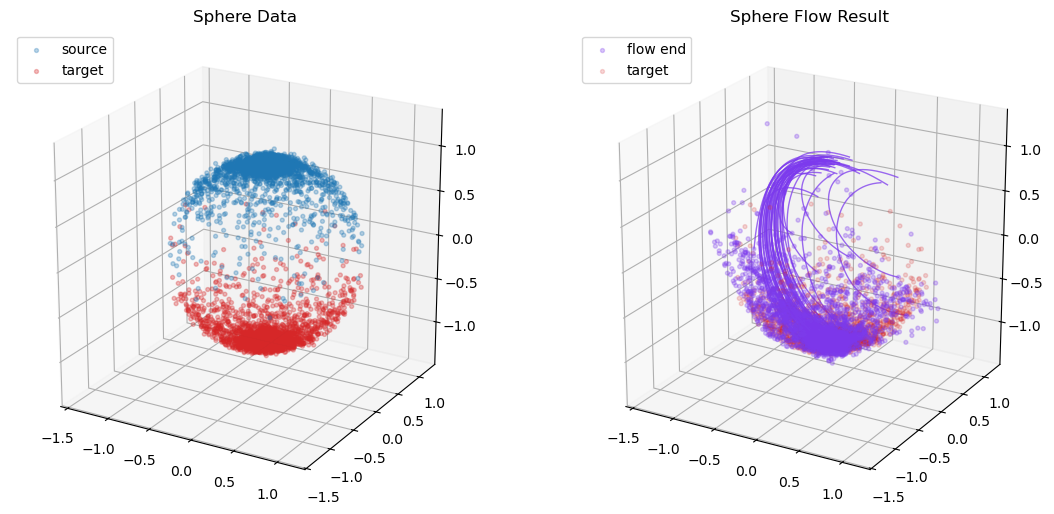

In [117]:
plot_training_result(result, n_traj=40, title_prefix="Sphere ")


In [118]:
save_training_gif(
    result,
    out_path="sphere_best.gif",
    max_points=800,
    fps=18,
    title_prefix="Sphere ",
)


## Torus Optimization

In [123]:
phi_hpo_torus = tune_interpolant(
    x0=torch.tensor(torus_x0, dtype=torch.float32),
    x1=torch.tensor(torus_x1, dtype=torch.float32),
    metric_ckpt_path="torus_paper_rbf_metric.pt",
    hidden_dims=(32, 64, 128, 256),
    hidden_layers_list=(2, 4, 6),
    learning_rates=(1e-4, 3e-4, 1e-3),
    batch_sizes=(64, 128, 256),
    steps_short=500,
    steps_long=3000,
    top_k=4,
    eval_batches=8,
    eval_batch_size=128,
    log=500,
    seed=0,
    device=device,
    save_dir="torus_hpo_phi",
)

best_phi_torus = phi_hpo_torus["best_config"]

v_hpo_torus = tune_velocity(
    x0=torch.tensor(torus_x0, dtype=torch.float32),
    x1=torch.tensor(torus_x1, dtype=torch.float32),
    metric_ckpt_path="torus_paper_rbf_metric.pt",
    phi_ckpt_path=phi_hpo_torus["best_ckpt_path"],
    phi_hidden_dim=best_phi_torus["phi_hidden_dim"],
    phi_hidden_layers=best_phi_torus["phi_hidden_layers"],
    hidden_dims=(32, 64, 128, 256),
    hidden_layers_list=(2, 4, 6),
    learning_rates=(1e-4, 3e-4, 1e-3),
    batch_sizes=(64, 128, 256),
    steps_short=800,
    steps_long=5000,
    top_k=4,
    eval_batches=8,
    eval_batch_size=128,
    eval_ode_steps=100,
    log=500,
    seed=0,
    device=device,
    save_dir="torus_hpo_v",
)


[phi] step 500/500 loss=49.844009
[phi] step 500/500 loss=147.179169
[phi] step 500/500 loss=422.363953
[phi] step 500/500 loss=12.513579
[phi] step 500/500 loss=14.590208
[phi] step 500/500 loss=19.293961
[phi] step 500/500 loss=15.955651
[phi] step 500/500 loss=11.381441
[phi] step 500/500 loss=11.755927
[phi] step 500/500 loss=60.364460
[phi] step 500/500 loss=17.311123
[phi] step 500/500 loss=29.338516
[phi] step 500/500 loss=13.738939
[phi] step 500/500 loss=10.891670
[phi] step 500/500 loss=13.655050
[phi] step 500/500 loss=12.003777
[phi] step 500/500 loss=13.198790
[phi] step 500/500 loss=11.748568
[phi] step 500/500 loss=15.011795
[phi] step 500/500 loss=15.926258
[phi] step 500/500 loss=18.538229
[phi] step 500/500 loss=11.027186
[phi] step 500/500 loss=16.054804
[phi] step 500/500 loss=13.760054
[phi] step 500/500 loss=13.167886
[phi] step 500/500 loss=14.460754
[phi] step 500/500 loss=12.871699
[phi] step 500/500 loss=45.013355
[phi] step 500/500 loss=42.549728
[phi] step 5

In [124]:
best_phi_torus = phi_hpo_torus["best_config"]
best_v_torus = v_hpo_torus["best_config"]

result_torus = run_training(
    x0=torch.tensor(torus_x0, dtype=torch.float32),
    x1=torch.tensor(torus_x1, dtype=torch.float32),
    metric_ckpt_path="torus_paper_rbf_metric.pt",
    phi_hidden_dim=best_phi_torus["phi_hidden_dim"],
    phi_hidden_layers=best_phi_torus["phi_hidden_layers"],
    v_hidden_dim=best_v_torus["v_hidden_dim"],
    v_hidden_layers=best_v_torus["v_hidden_layers"],
    phi_steps=best_phi_torus["phi_steps"],
    v_steps=best_v_torus["v_steps"],
    batch_size=best_v_torus["batch_size"],
    phi_lr=best_phi_torus["phi_lr"],
    v_lr=best_v_torus["v_lr"],
    ode_steps=150,
    log=500,
    device=device,
)


[phi] step 500/3000 loss=11.378776
[phi] step 1000/3000 loss=10.373558
[phi] step 1500/3000 loss=10.797140
[phi] step 2000/3000 loss=11.139254
[phi] step 2500/3000 loss=10.262836
[phi] step 3000/3000 loss=10.456505
Interpolant Training Done
[v] step 500/5000 loss=0.505381
[v] step 1000/5000 loss=0.608087
[v] step 1500/5000 loss=0.396362
[v] step 2000/5000 loss=0.491261
[v] step 2500/5000 loss=0.367672
[v] step 3000/5000 loss=0.357496
[v] step 3500/5000 loss=0.273789
[v] step 4000/5000 loss=0.348454
[v] step 4500/5000 loss=0.267826
[v] step 5000/5000 loss=0.271961
Velocity Net Training Done
Flow Integrated
Trajectories Acquired


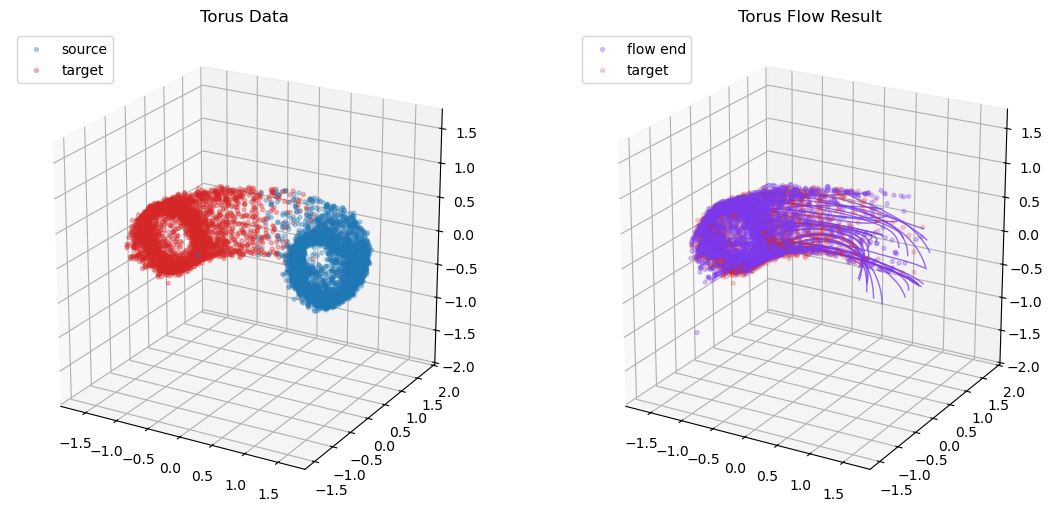

In [125]:
plot_training_result(result_torus, n_traj=40, title_prefix="Torus ")


In [126]:
save_training_gif(
    result_torus,
    out_path="torus_best.gif",
    max_points=800,
    fps=18,
    title_prefix="Torus ",
)


## Genus-2 Optimization


In [132]:
phi_hpo_genus2 = tune_interpolant(
    x0=torch.tensor(genus2_x0, dtype=torch.float32),
    x1=torch.tensor(genus2_x1, dtype=torch.float32),
    metric_ckpt_path="genus2_paper_rbf_metric.pt",
    hidden_dims=(32, 64, 128, 256),
    hidden_layers_list=(2, 4, 6),
    learning_rates=(1e-4, 3e-4, 1e-3),
    batch_sizes=(64, 128, 256),
    steps_short=500,
    steps_long=3000,
    top_k=4,
    eval_batches=8,
    eval_batch_size=128,
    log=500,
    seed=0,
    device=device,
    save_dir="genus2_hpo_phi",
)

best_phi_genus2 = phi_hpo_genus2["best_config"]

v_hpo_genus2 = tune_velocity(
    x0=torch.tensor(genus2_x0, dtype=torch.float32),
    x1=torch.tensor(genus2_x1, dtype=torch.float32),
    metric_ckpt_path="genus2_paper_rbf_metric.pt",
    phi_ckpt_path=phi_hpo_genus2["best_ckpt_path"],
    phi_hidden_dim=best_phi_genus2["phi_hidden_dim"],
    phi_hidden_layers=best_phi_genus2["phi_hidden_layers"],
    hidden_dims=(32, 64, 128, 256),
    hidden_layers_list=(2, 4, 6),
    learning_rates=(1e-4, 3e-4, 1e-3),
    batch_sizes=(64, 128, 256),
    steps_short=800,
    steps_long=5000,
    top_k=4,
    eval_batches=8,
    eval_batch_size=128,
    eval_ode_steps=100,
    log=500,
    seed=0,
    device=device,
    save_dir="genus2_hpo_v",
)


[phi] step 500/500 loss=214.987335
[phi] step 500/500 loss=182.194901
[phi] step 500/500 loss=67.248352
[phi] step 500/500 loss=34.347980
[phi] step 500/500 loss=52.091877
[phi] step 500/500 loss=36.907558
[phi] step 500/500 loss=38.586441
[phi] step 500/500 loss=30.240843
[phi] step 500/500 loss=43.012264
[phi] step 500/500 loss=119.222534
[phi] step 500/500 loss=77.714134
[phi] step 500/500 loss=90.601364
[phi] step 500/500 loss=36.416729
[phi] step 500/500 loss=76.057419
[phi] step 500/500 loss=58.601204
[phi] step 500/500 loss=65.965080
[phi] step 500/500 loss=19.084209
[phi] step 500/500 loss=21.883656
[phi] step 500/500 loss=56.983826
[phi] step 500/500 loss=44.783936
[phi] step 500/500 loss=64.598862
[phi] step 500/500 loss=81.435074
[phi] step 500/500 loss=49.458279
[phi] step 500/500 loss=45.501900
[phi] step 500/500 loss=41.322502
[phi] step 500/500 loss=11.392918
[phi] step 500/500 loss=34.281178
[phi] step 500/500 loss=66.090767
[phi] step 500/500 loss=64.860153
[phi] step 

In [133]:
best_phi_genus2 = phi_hpo_genus2["best_config"]
best_v_genus2 = v_hpo_genus2["best_config"]

result_genus2 = run_training(
    x0=torch.tensor(genus2_x0, dtype=torch.float32),
    x1=torch.tensor(genus2_x1, dtype=torch.float32),
    metric_ckpt_path="genus2_paper_rbf_metric.pt",
    phi_hidden_dim=best_phi_genus2["phi_hidden_dim"],
    phi_hidden_layers=best_phi_genus2["phi_hidden_layers"],
    v_hidden_dim=best_v_genus2["v_hidden_dim"],
    v_hidden_layers=best_v_genus2["v_hidden_layers"],
    phi_steps=best_phi_genus2["phi_steps"],
    v_steps=best_v_genus2["v_steps"],
    batch_size=best_v_genus2["batch_size"],
    phi_lr=best_phi_genus2["phi_lr"],
    v_lr=best_v_genus2["v_lr"],
    ode_steps=150,
    log=500,
    device=device,
)


[phi] step 500/3000 loss=15.288040
[phi] step 1000/3000 loss=10.937972
[phi] step 1500/3000 loss=8.047459
[phi] step 2000/3000 loss=8.316209
[phi] step 2500/3000 loss=8.641080
[phi] step 3000/3000 loss=6.846275
Interpolant Training Done
[v] step 500/5000 loss=1.171053
[v] step 1000/5000 loss=0.579495
[v] step 1500/5000 loss=0.692140
[v] step 2000/5000 loss=2.907620
[v] step 2500/5000 loss=0.584398
[v] step 3000/5000 loss=0.744241
[v] step 3500/5000 loss=2.212691
[v] step 4000/5000 loss=0.598171
[v] step 4500/5000 loss=0.209925
[v] step 5000/5000 loss=0.589932
Velocity Net Training Done
Flow Integrated
Trajectories Acquired


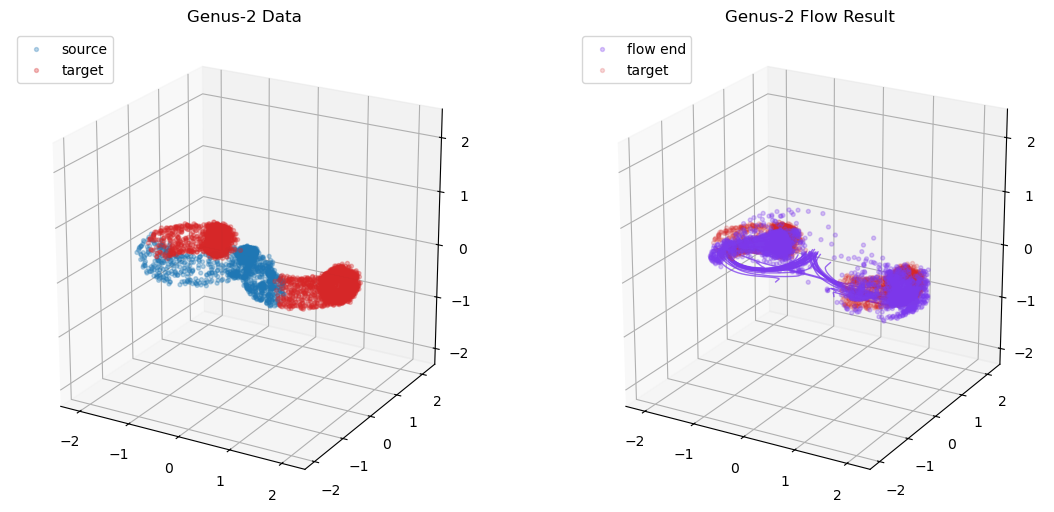

In [134]:
plot_training_result(result_genus2, n_traj=40, title_prefix="Genus-2 ")


In [135]:
save_training_gif(
    result_genus2,
    out_path="genus2_best.gif",
    max_points=600,
    fps=14,
    title_prefix="Genus-2 ",
)


# Summary

The outputs for the three setups are stored as GIFs. There are multiple positive things to point to:

1. The data stays on the manifolds well and also converges onto the final distribution.
2. Even in the genus-2 case, it respects both cycles and splits up to join in the spatially disjoint final distributions.
3. The main bottleneck is the need for all three networks to work well. If *any* one of them fails at its respective task, the other ones cannot do well.
4. For each network to perform well, it required a non-trivial amount of:
  - Data
  - Network depth
  - Network width
5. For the hyperparameter optimization process, we would have appreciated having GPU access. 
6. We only used toy datasets here. If one was to use high-dimensional gene space data, one would surely have to use GPUs and larger networks to achieve good performance.

